# RWSWVI-92 Diffraction Direction Calculation.py

This notebook demonstrates the most recent diffraction direction calculation functionality.

The functionality includes:
- Open case: waves can reach location unobstructed
- Overlapping breakwaters: nearest breakwater determines direction
- Shadow zone: waves diffract around both breakwaters
- Single breakwater diffraction: waves diffract around one breakwater

In [1]:
# Standard imports
import os, sys, shutil, math
import numpy as np

import matplotlib.pyplot as plt

%reload_ext autoreload 
%autoreload 2

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"# HB Havens imports


In [2]:
owd = os.getcwd()
testdir = os.path.dirname(owd)
trunkdir = os.path.dirname(testdir)

sys.path.append(testdir)
sys.path.append(trunkdir)

tempdir = os.path.join(os.path.dirname(trunkdir),'temp')
if not os.path.isdir(tempdir):
    os.mkdir(tempdir)

In [3]:
from hbhavens.core.models import MainModel
import hbhavens.core.geometry as geometry
import common

## Helper Functions for Visualization

These functions help visualize the diffraction results but use the core functionality from simple.py.

In [4]:
def plot_diffraction_results(model, hlid):

    get_direction = model.simple_calculation.diffraction.get_direction

    # Get locations for the hydraulic load(s)
    if not isinstance(hlid, list):
        hlid = [hlid]
    
    first_hlid = hlid[0]
    locs = model.simple_calculation.diffraction.output.loc[(slice(None), first_hlid), :].index.get_level_values(0)
    
    for ifig, id in enumerate(hlid):
        # Use plot_schematisation from the model's schematisation (as requested)
        fig, ax = model.schematisation.plot_schematisation(buffer=200, locations=False, figsize=(15,15))
        
        # Add result locations
        _ = ax.scatter(model.schematisation.result_locations.geometry.x, 
                     model.schematisation.result_locations.geometry.y, 
                     c='k', s=5., zorder=20, label='Uitvoerlocaties')

        # Calculate scale for arrows
        scale = 40 + (ax.bbox.bounds[2] - ax.bbox.bounds[0]) / 50

        # Plot the wave direction
        wind_direction = model.hydraulic_loads.loc[id,'Wind direction']
        wave_direction = model.simple_calculation.diffraction.output.loc[(slice(None), id),'Wave direction'].iloc[0]
        supportloc = model.schematisation.entrance.centroid.coords[0]
        
        # Draw wave direction arrow from entrance
        import hbhavens.core.geometry as geometry
        line = geometry.extend_point_to_linestring(supportloc, wave_direction, (-scale, scale))
        _ = ax.arrow(*line[0], *(line[1] - line[0]), length_includes_head=True, 
                    head_width=scale/4, head_length=scale/2, color='k', alpha=0.7, 
                    label='Wave direction')

        # Get breakwater heads mapping
        try:
            heads = model.simple_calculation.diffraction.map_breakwaterheads()
        except:
            heads = {'left': None, 'right': None}

        # Plot breakwater heads
        if isinstance(heads.get('left'), int):
            left_head = model.schematisation.breakwaters['breakwaterhead'].iloc[heads['left']]
            _ = ax.plot(*left_head.coords.xy, 'o', color='green', markersize=8, 
                      label='Left breakwater head')
        if isinstance(heads.get('right'), int):
            right_head = model.schematisation.breakwaters['breakwaterhead'].iloc[heads['right']]
            _ = ax.plot(*right_head.coords.xy, 'o', color='red', markersize=8, 
                      label='Right breakwater head')

        # Plot the diffraction results for each location
        for il, loc in enumerate(locs):
            # Get diffraction data for current hydraulic load ID
            loc_data = model.simple_calculation.diffraction.output.loc[(loc, id), :]
            dirs = loc_data['Diffraction direction']
            
            # Fix: Ensure diffraction_case is a scalar value, not a Series
            diffraction_case_raw = loc_data.get('Diffraction case', 'Unknown')
            if hasattr(diffraction_case_raw, 'iloc'):
                # If it's a Series, get the first (and should be only) value
                diffraction_case = diffraction_case_raw.iloc[0] if len(diffraction_case_raw) > 0 else 'Unknown'
            else:
                # If it's already a scalar
                diffraction_case = diffraction_case_raw
            
            # Get result location geometry
            geom = model.schematisation.result_locations.loc[
                model.schematisation.result_locations['Naam'] == loc, 'geometry'].values[0]

            # Color coding based on "Diffraction case" column (as requested)
            if diffraction_case == 'Open':
                c = 'blue'
                case_label = 'Open'
            elif diffraction_case == 'Overlapping breakwaters':
                c = 'orange'
                case_label = 'Overlapping'
            elif diffraction_case == 'Shadow zone':
                c = 'black'
                case_label = 'Shadow'
            elif diffraction_case == 'Diffracted around DirLeft':
                c = 'green'
                case_label = 'Left diffraction'
            elif diffraction_case == 'Diffracted around DirRight':
                c = 'red'
                case_label = 'Right diffraction'
            else:
                c = 'grey'
                case_label = 'Unknown'

            # Plot diffraction direction arrow
            line = geometry.extend_point_to_linestring(geom, dirs, (-scale*0.8, scale*0.8))
            _ = ax.arrow(*line[0], *(line[1] - line[0]), length_includes_head=True, 
                        head_width=scale/6, head_length=scale/3, color=c, zorder=20, alpha=0.8)

            # Draw diffraction line from location to entrance intersection (similar to ResultsPlotter)
            try:
                from shapely.geometry import LineString
                import shapely
                
                # Get entrance line direction
                entrance_start = shapely.Point(model.schematisation.entrance.coords[0])
                entrance_end = shapely.Point(model.schematisation.entrance.coords[-1])
                entrance_angle = get_direction(entrance_start, entrance_end)
                entrance_line = geometry.extend_point_to_linestring(
                    entrance_start.coords[0], entrance_angle, (-10000, 10000), as_LineString=True)

                # Create diffraction ray line
                diffraction_ray = geometry.extend_point_to_linestring(
                    (geom.x, geom.y), dirs, (-10000, 10000))
                ray_geom = LineString(diffraction_ray)

                # Find intersection with entrance line
                intersection = ray_geom.intersection(entrance_line)

                if hasattr(intersection, 'x') and hasattr(intersection, 'y'):
                    # Draw line from location to intersection point
                    _ = ax.plot([geom.x, intersection.x], [geom.y, intersection.y], 
                              color=c, linestyle='--', linewidth=1.0, alpha=0.6)
            except Exception as e:
                print(f"Warning: Could not plot diffraction line for {loc}: {e}")

        # Create custom legend entries for diffraction cases
        legend_elements = []
        cases_seen = set()
        
        # Add diffraction case colors to legend
        for loc in locs:
            loc_data = model.simple_calculation.diffraction.output.loc[(loc, id), :]
            # Fix: Same fix for legend generation
            diffraction_case_raw = loc_data.get('Diffraction case', 'Unknown')
            if hasattr(diffraction_case_raw, 'iloc'):
                diffraction_case = diffraction_case_raw.iloc[0] if len(diffraction_case_raw) > 0 else 'Unknown'
            else:
                diffraction_case = diffraction_case_raw
            
            if diffraction_case not in cases_seen:
                cases_seen.add(diffraction_case)
                if diffraction_case == 'Open':
                    legend_elements.append(plt.Line2D([0], [0], color='blue', lw=2, label='Open'))
                elif diffraction_case == 'Overlapping breakwaters':
                    legend_elements.append(plt.Line2D([0], [0], color='orange', lw=2, label='Overlapping'))
                elif diffraction_case == 'Shadow zone':
                    legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='Shadow zone'))
                elif diffraction_case == 'Diffracted around DirLeft':
                    legend_elements.append(plt.Line2D([0], [0], color='green', lw=2, label='Left diffraction'))
                elif diffraction_case == 'Diffracted around DirRight':
                    legend_elements.append(plt.Line2D([0], [0], color='red', lw=2, label='Right diffraction'))

        # Combine with existing legend
        if ax.get_legend():
            existing_handles, existing_labels = ax.get_legend_handles_labels()
            all_handles = existing_handles + legend_elements
            all_labels = existing_labels + [elem.get_label() for elem in legend_elements]
        else:
            all_handles = legend_elements
            all_labels = [elem.get_label() for elem in legend_elements]
        
        _ = ax.legend(handles=all_handles, labels=all_labels, loc='lower left')
        _ = ax.set_title(f'Wind direction {wind_direction}°N, Wave direction {wave_direction}°N')

        plt.tight_layout()
        plt.show()


## Analytische testgevallen

In [5]:
model = MainModel()
get_direction = model.simple_calculation.diffraction.get_direction
diffracted_direction = model.simple_calculation.diffraction.diffracted_direction

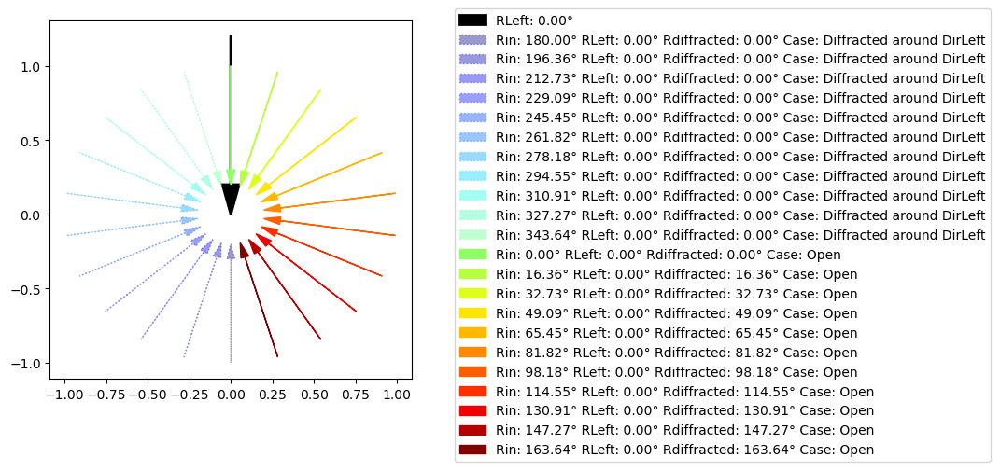

In [6]:
# single breakwater left
N = 22
cm = plt.cm.jet(np.linspace(0,1,N))

RLeft = 0

fig, ax = plt.subplots(figsize=(5,5))
_ = ax.arrow(-1.2*math.cos(math.radians(270 - RLeft)), -1.2*math.sin(math.radians(270 - RLeft)), 1.*math.cos(math.radians(270 - RLeft)), 1.*math.sin(math.radians(270 - RLeft)),
            head_width=0.1, head_length=0.2, lw=2., fc='k', ec='k', label=f'RLeft: {RLeft:.2f}°')

for i,D in enumerate(np.arange(0, 360, 360/N)):

    Rin = get_direction((math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D))), (-0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D))))
    Ddiffracted, Cdiffracted = diffracted_direction(Rin, RLeft, None)

    if Cdiffracted == 'Open':
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], label=f'Rin: {Rin:.2f}° RLeft: {RLeft:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')
    else:
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], alpha=0.4, ls =':', label=f'Rin: {Rin:.2f}° RLeft: {RLeft:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')

_ = plt.legend(bbox_to_anchor=(1.1, 1.05))

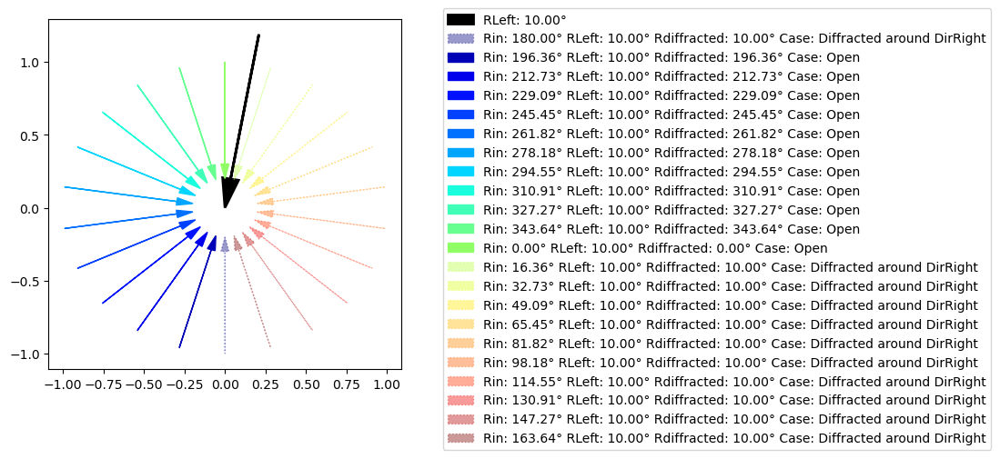

In [7]:
# single breakwater right
N = 22
cm = plt.cm.jet(np.linspace(0,1,N))

RRight = 10

fig, ax = plt.subplots(figsize=(5,5))
_ = ax.arrow(-1.2*math.cos(math.radians(270 - RRight)), -1.2*math.sin(math.radians(270 - RRight)), 1.*math.cos(math.radians(270 - RRight)), 1.*math.sin(math.radians(270 - RRight)),
            head_width=0.1, head_length=0.2, lw=2., fc='k', ec='k', label=f'RLeft: {RRight:.2f}°')

for i,D in enumerate(np.arange(0, 360, 360/N)):

    Rin = get_direction((math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D))), (-0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D))))
    Ddiffracted, Cdiffracted = diffracted_direction(Rin, None, RRight)

    if Cdiffracted == 'Open':
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], label=f'Rin: {Rin:.2f}° RLeft: {RRight:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')
    else:
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], alpha=0.4, ls =':', label=f'Rin: {Rin:.2f}° RLeft: {RRight:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')

_ = plt.legend(bbox_to_anchor=(1.1, 1.05))

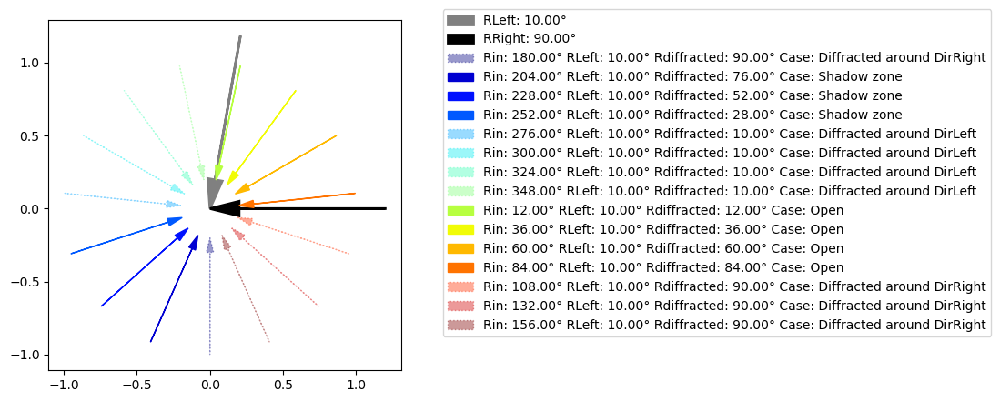

In [8]:
# Double breakwater, no overlap
N = 15
cm = plt.cm.jet(np.linspace(0,1,N))

RLeft = 10
RRight = 90

fig, ax = plt.subplots(figsize=(5,5))
_ = ax.arrow(-1.2*math.cos(math.radians(270 - RLeft)), -1.2*math.sin(math.radians(270 - RLeft)), 1.*math.cos(math.radians(270 - RLeft)), 1.*math.sin(math.radians(270 - RLeft)),
            head_width=0.1, head_length=0.2, lw=2., fc='gray', ec='gray', label=f'RLeft: {RLeft:.2f}°')
_ = ax.arrow(-1.2*math.cos(math.radians(270 - RRight)), -1.2*math.sin(math.radians(270 - RRight)), 1.*math.cos(math.radians(270 - RRight)), 1.*math.sin(math.radians(270 - RRight)),
            head_width=0.1, head_length=0.2, lw=2., fc='k', ec='k', label=f'RRight: {RRight:.2f}°')

for i,D in enumerate(np.arange(0, 360, 360/N)):

    Rin = get_direction((math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D))), (-0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D))))
    Ddiffracted, Cdiffracted = diffracted_direction(Rin, RLeft, RRight)

    if Cdiffracted == 'Open':
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], label=f'Rin: {Rin:.2f}° RLeft: {RLeft:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')
    elif Cdiffracted == 'Shadow zone':
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], label=f'Rin: {Rin:.2f}° RLeft: {RLeft:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')
    else:
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], alpha=0.4, ls =':', label=f'Rin: {Rin:.2f}° RLeft: {RLeft:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')

_ = plt.legend(bbox_to_anchor=(1.1, 1.05))

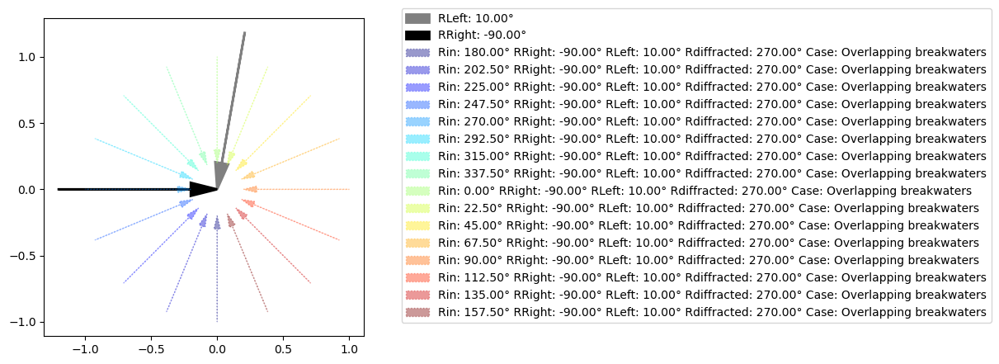

In [9]:
# Double breakwater, with overlap
N = 16
cm = plt.cm.jet(np.linspace(0,1,N))

RLeft = 10
RRight = -90
DLeft = 40.
DRight = 20.

fig, ax = plt.subplots(figsize=(5,5))
_ = ax.arrow(-1.2*math.cos(math.radians(270 - RLeft)), -1.2*math.sin(math.radians(270 - RLeft)), 1.*math.cos(math.radians(270 - RLeft)), 1.*math.sin(math.radians(270 - RLeft)),
            head_width=0.1, head_length=0.2, lw=2., fc='gray', ec='gray', label=f'RLeft: {RLeft:.2f}°')
_ = ax.arrow(-1.2*math.cos(math.radians(270 - RRight)), -1.2*math.sin(math.radians(270 - RRight)), 1.*math.cos(math.radians(270 - RRight)), 1.*math.sin(math.radians(270 - RRight)),
            head_width=0.1, head_length=0.2, lw=2., fc='k', ec='k', label=f'RRight: {RRight:.2f}°')

for i,D in enumerate(np.arange(0, 360, 360/N)):

    Rin = get_direction((math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D))), (-0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D))))

    DHeads = [RLeft, RRight]
    RNearestHead = DHeads[np.argmin([DLeft, DRight])]
    Ddiffracted, Cdiffracted = diffracted_direction(Rin, RLeft, RRight, RNearestHead)

    if Cdiffracted == 'Open':
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], label=f'Rin: {Rin:.2f}° RLeft: {RLeft:.2f}° RRight: {RRight:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')
    elif Cdiffracted == 'Shadow zone':
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], label=f'Rin: {Rin:.2f}° RLeft: {RLeft:.2f}° RRight: {RRight:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')
    else:
        _ = ax.arrow(math.cos(math.radians(270 - D)), math.sin(math.radians(270 - D)), -0.7*math.cos(math.radians(270 - D)), -0.7*math.sin(math.radians(270 - D)),
                    head_width=0.05, head_length=0.1, fc=cm[i], ec=cm[i], alpha=0.4, ls =':', label=f'Rin: {Rin:.2f}° RRight: {RRight:.2f}° RLeft: {RLeft:.2f}° Rdiffracted: {Ddiffracted:.2f}° Case: {Cdiffracted}')

_ = plt.legend(bbox_to_anchor=(1.1, 1.05))

## Test Case 1: Krammersluizen

Standard two-breakwater configuration demonstrating the different diffraction cases.

In [10]:
case = 'krammersluizen'
casedir = os.path.join(tempdir,case)
if os.path.isdir(casedir):
    shutil.rmtree(casedir)

datadir = os.path.join(trunkdir, 'tests', 'data', case)
paths = {
    'harborarea': os.path.join(datadir, 'shapes', 'haventerrein.shp'),
    'breakwater': os.path.join(datadir, 'shapes', 'havendammen_oost.shp'),
    'result_locations': os.path.join(datadir, 'shapes', 'uitvoerlocaties_oost.shp'),
    'hrd': os.path.join(datadir, 'databases', 'WBI2017_VolkerakZoommeer_217_v01_HBHavens.sqlite'),
}
trajecten = ['217']
bedlevel = -6.5
supportlocation = 'VZ_3_00499'

In [ ]:
model = MainModel()
model.project.settings['project']['name'] = case
model.project.settings['project']['user']['email'] = 'benit@hkv.nl'
model.project.settings['project']['user']['name'] = 'Matthijs Bénit'

model.project.save_as(os.path.join(tempdir, case, case + '.json'))

common.add_schematisation(model, paths=paths, supportlocationname=supportlocation, trajecten=trajecten, bedlevel=bedlevel)

# Calculate wave processes
model.simple_calculation.run_all(['Lokale golfgroei', 'Transmissie', 'Diffractie', 'Golfbreking'])
model.simple_calculation.combinedresults.run(['Lokale golfgroei', 'Diffractie', 'Transmissie', 'Golfbreking'])
model.simple_calculation.mainmodel.project.settings['simple']['finished'] = True
model.simple_calculation.save_results()

# Save results
model.project.save()
model.save_tables()

In [12]:
# selecteer de laatste van elke wind richting en specifieke basisstochastwaarden (varierende Water level Maasmond)
# merk op dat de golfrichting gelijk is aan de windrichting. Blijkbaar Bretschneider input (BOI = SWAN in VZM)
hlid = [model.hydraulic_loads.loc[
    (model.hydraulic_loads['ClosingSituationId'] == 1) & 
    (model.hydraulic_loads['Wind direction'] == wd) & 
    (model.hydraulic_loads['Wind speed'] == 30.) & 
    (model.hydraulic_loads['Discharge Lobith'] == 8000) &
    (model.hydraulic_loads['Lake level VZM'] == 1.8) 
    ].index[-1] for wd in model.hydraulic_loads.loc[:,'Wind direction'].unique()]
model.hydraulic_loads.loc[hlid]

,ClosingSituationId,Wind direction,Discharge Lobith,Water level Maasmond,Wind speed,Lake level VZM,h,Hs,Tp,"Tm-1,0",Wave direction,Storage situation VZM,Description
HydraulicLoadId,,,,,,,,,,,,,
1134626,1,22.5,8000.0,1.36,30.0,1.8,1.8001,1.1556,3.9226,3.5660,22.5,0.0,K=01 D=022.5 Q=08000 M=1.36 U=30 M=1.80
1134651,1,45.0,8000.0,1.36,30.0,1.8,1.8006,1.1724,3.9753,3.6139,45.0,0.0,K=01 D=045.0 Q=08000 M=1.36 U=30 M=1.80
1134676,1,67.5,8000.0,1.36,30.0,1.8,1.9104,1.3087,4.2963,3.9057,67.5,0.0,K=01 D=067.5 Q=08000 M=1.36 U=30 M=1.80
1134701,1,90.0,8000.0,1.36,30.0,1.8,2.0141,1.3859,4.5335,4.1214,90.0,0.0,K=01 D=090.0 Q=08000 M=1.36 U=30 M=1.80
1134726,1,112.5,8000.0,1.36,30.0,1.8,2.0950,1.5291,4.7507,4.3188,112.5,0.0,K=01 D=112.5 Q=08000 M=1.36 U=30 M=1.80
1134751,1,135.0,8000.0,1.36,30.0,1.8,2.1203,1.6253,4.8282,4.3893,135.0,0.0,K=01 D=135.0 Q=08000 M=1.36 U=30 M=1.80
1134776,1,157.5,8000.0,1.36,30.0,1.8,2.0801,1.0642,4.1196,3.7450,157.5,0.0,K=01 D=157.5 Q=08000 M=1.36 U=30 M=1.80
1134801,1,180.0,8000.0,1.36,30.0,1.8,2.0127,1.1202,3.9826,3.6206,180.0,0.0,K=01 D=180.0 Q=08000 M=1.36 U=30 M=1.80
1134826,1,202.5,8000.0,1.36,30.0,1.8,1.9282,0.8244,3.5303,3.2094,202.5,0.0,K=01 D=202.5 Q=08000 M=1.36 U=30 M=1.80


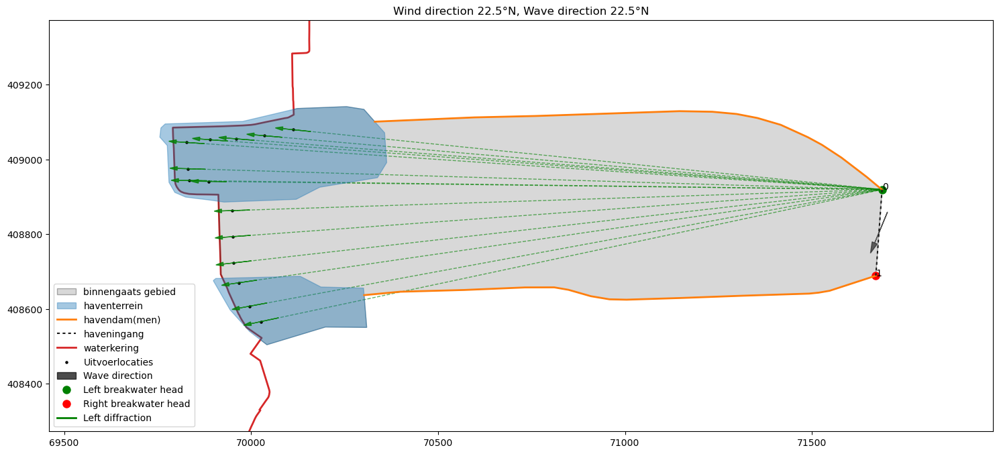

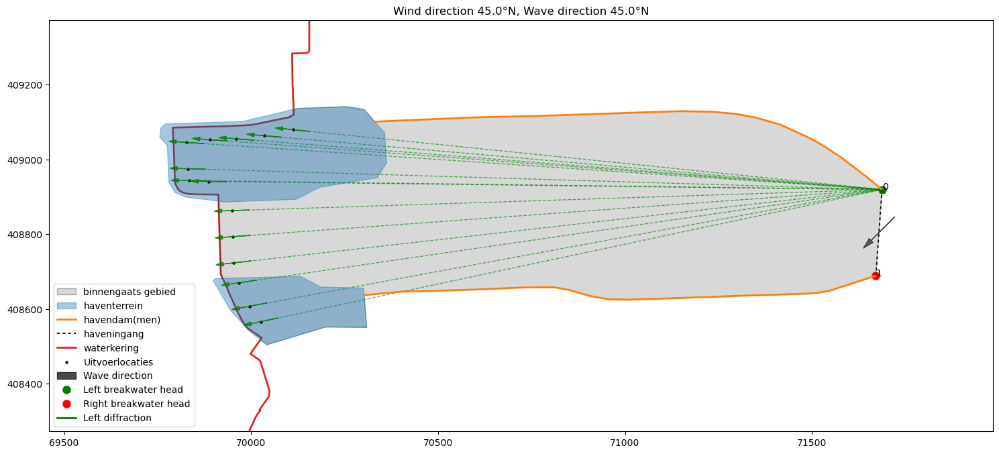

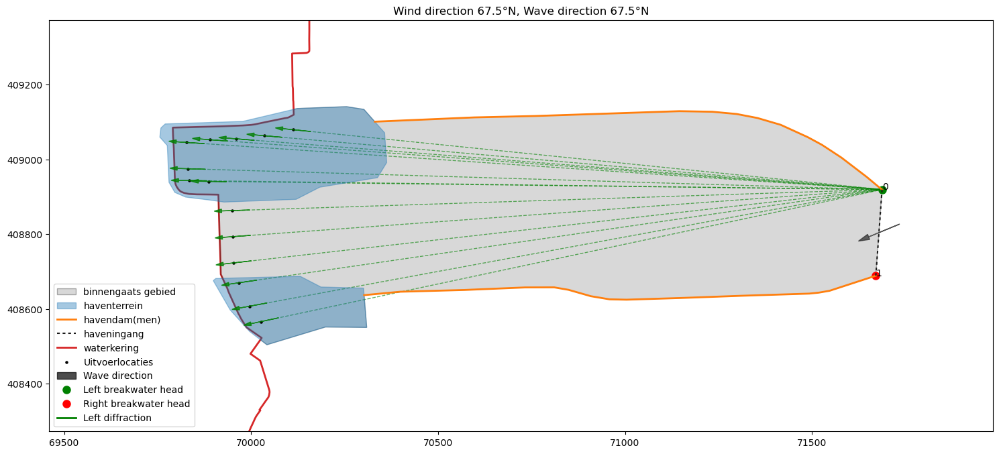

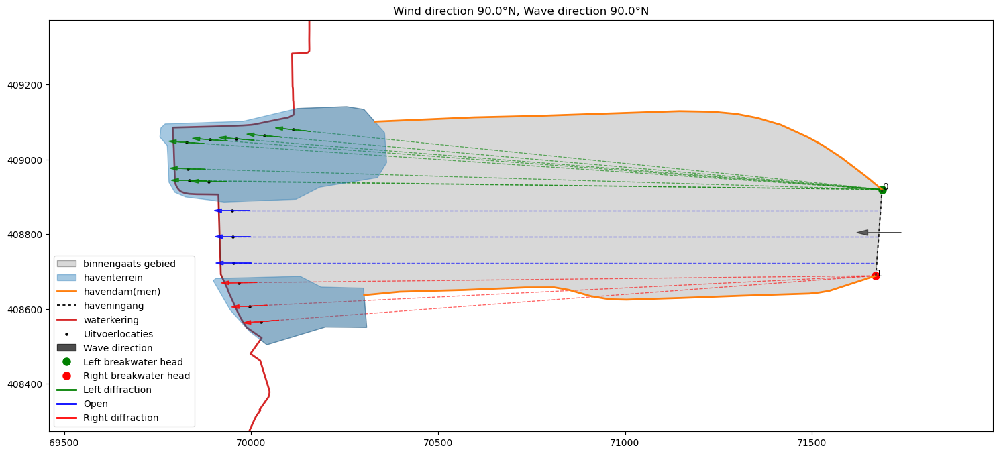

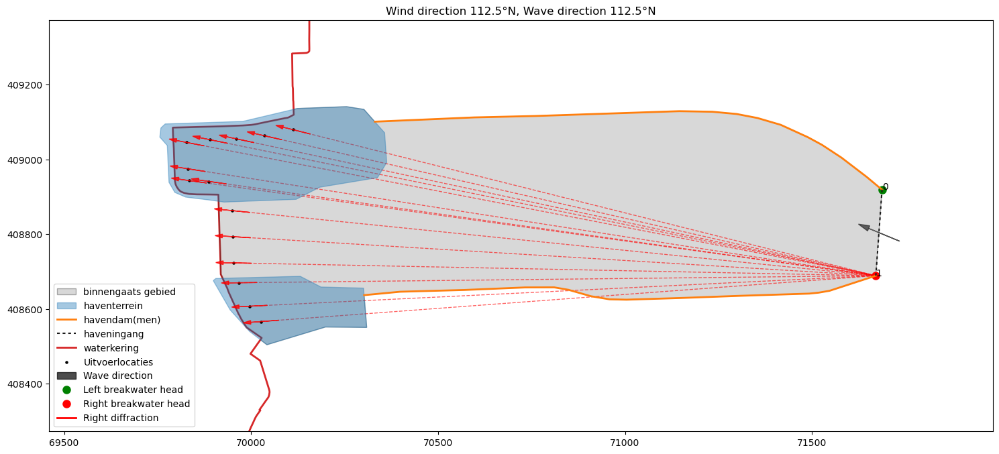

...

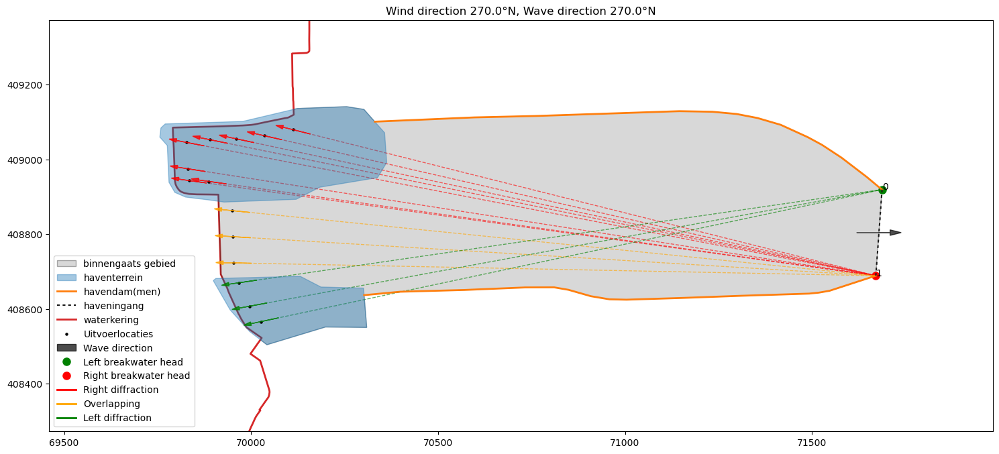

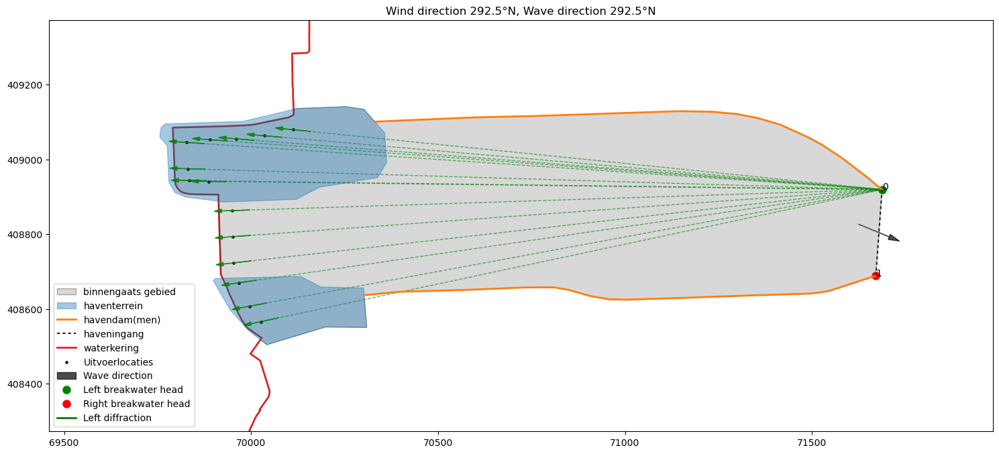

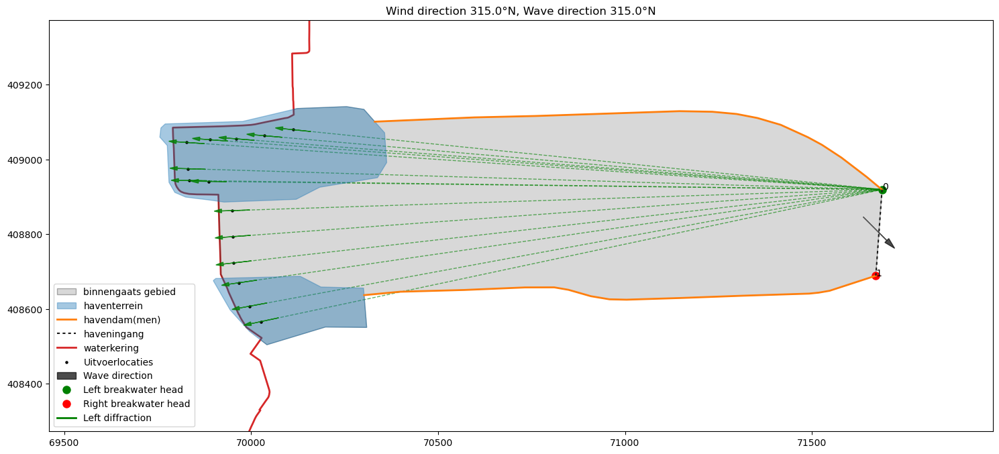

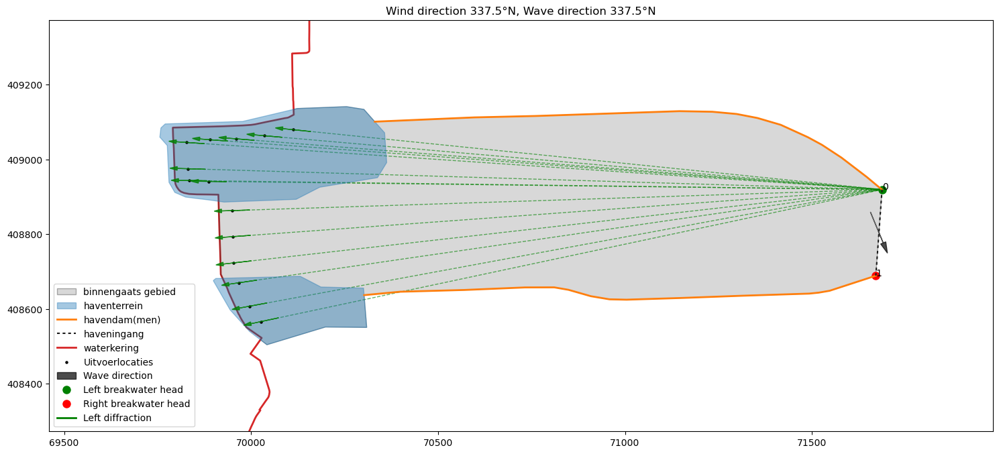

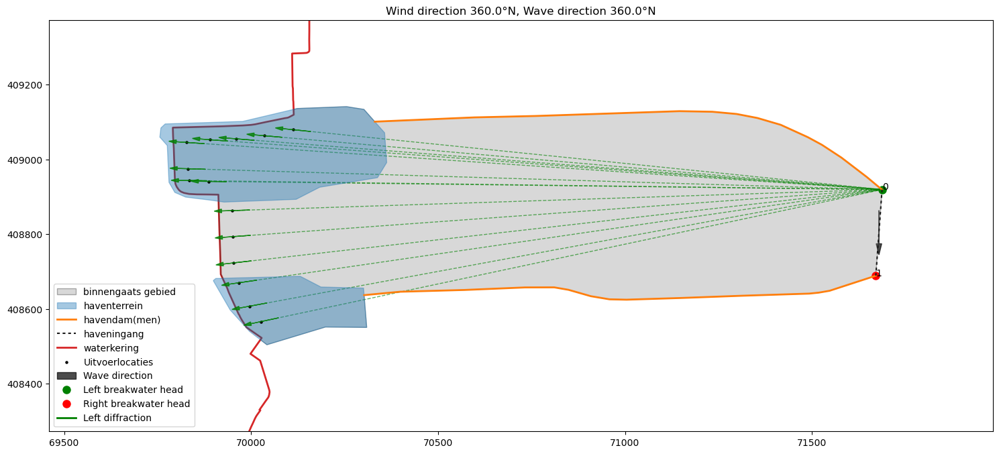

In [13]:
plot_diffraction_results(model, hlid)

## Test Case 2: Vlissingen

Coastal harbor entrance configuration.

In [14]:
case = 'vlissingen'
casedir = os.path.join(tempdir,case)
if os.path.isdir(casedir):
    shutil.rmtree(casedir)

datadir = os.path.join(trunkdir, 'tests', 'data', case)
paths = {
    'harborarea': os.path.join(datadir, 'shapes', 'haventerrein.shp'),
    'breakwater': os.path.join(datadir, 'shapes', 'havendammen.shp'),
    'result_locations': os.path.join(datadir, 'shapes', 'uitvoerlocaties.shp'),
    'hrd': os.path.join(datadir, 'databases', 'WBI2017_Westerschelde_29-3_29-4_v01.sqlite'),
}
trajecten = ['29-2','29-3']
bedlevel = -10.0
supportlocation = 'WS_1_29-3_dk_00024'
entrance =(31019., 385255.)


In [15]:
model = MainModel()
model.project.settings['project']['name'] = case
model.project.settings['project']['user']['email'] = 'benit@hkv.nl'
model.project.settings['project']['user']['name'] = 'Matthijs Bénit'

model.project.save_as(os.path.join(tempdir, case + '.json'))

common.add_schematisation(model, paths=paths, supportlocationname=supportlocation, trajecten=trajecten, bedlevel=bedlevel, entrance_coordinate=entrance)

model.simple_calculation.run_all(['Lokale golfgroei', 'Transmissie', 'Diffractie', 'Golfbreking'])
model.simple_calculation.combinedresults.run(['Lokale golfgroei', 'Diffractie', 'Transmissie', 'Golfbreking'])
model.simple_calculation.mainmodel.project.settings['simple']['finished'] = True
model.simple_calculation.save_results()

# Save results
model.project.save()
model.save_tables()

In [16]:
hlid = [model.hydraulic_loads.loc[
    (model.hydraulic_loads['ClosingSituationId'] == 1) &
    (model.hydraulic_loads['Wind speed'] == 30.) &
    (model.hydraulic_loads['Water level'] == 5.) 
    ].index[-1] for wd in model.hydraulic_loads.loc[:,'Wind direction'].unique()]
model.hydraulic_loads.loc[hlid]

,ClosingSituationId,Wind direction,Wind speed,Water level,Hs,"Tm-1,0",Wave direction,Description
HydraulicLoadId,,,,,,,,
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0
24925,1,360.0,30.0,5.0,1.1508,4.1201,315.244,D=360.0 U=30 h=5.0


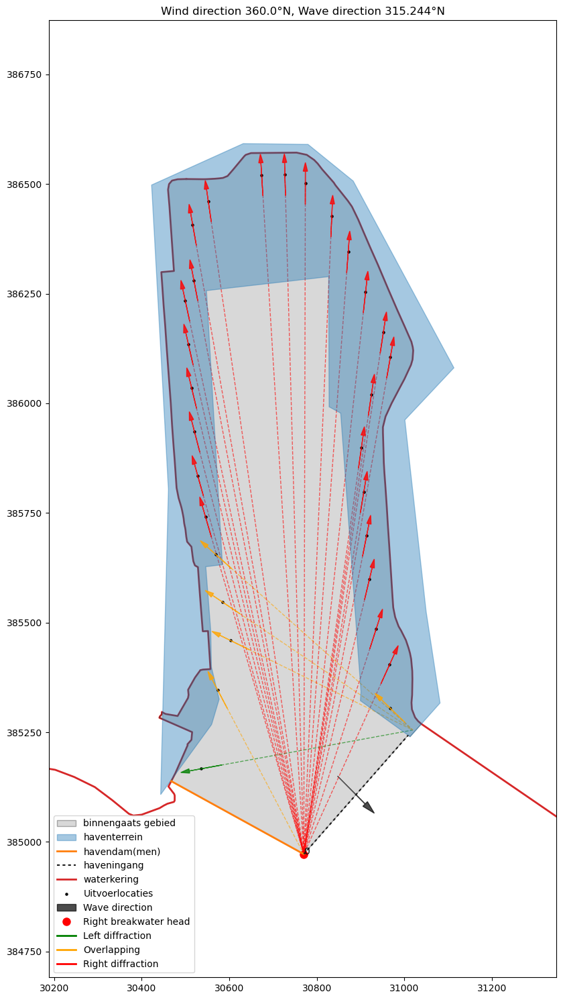

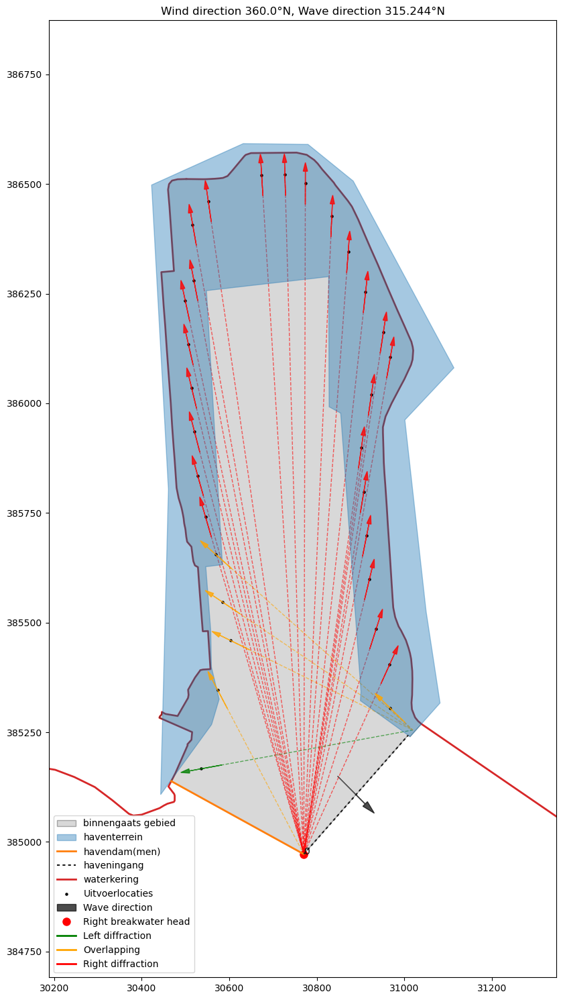

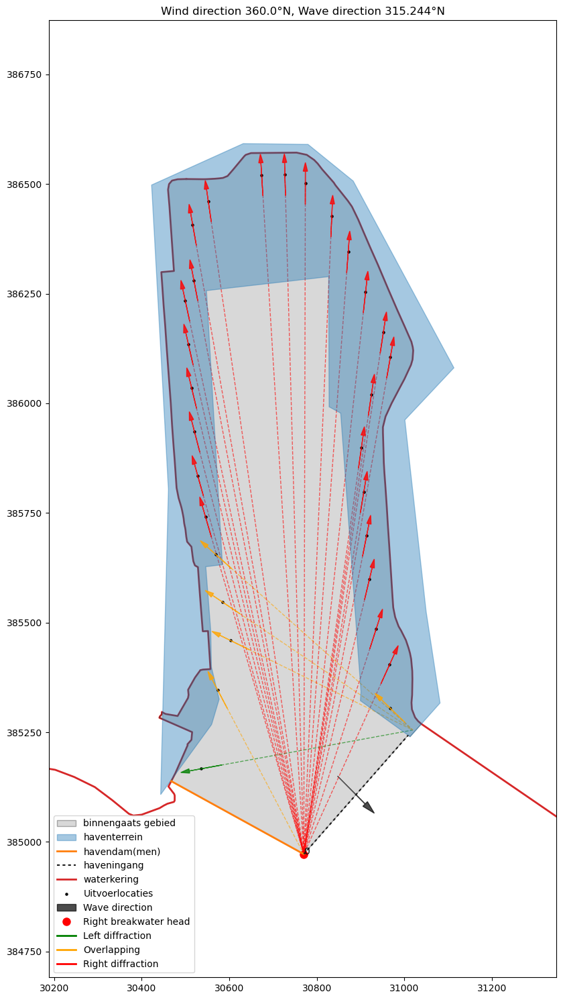

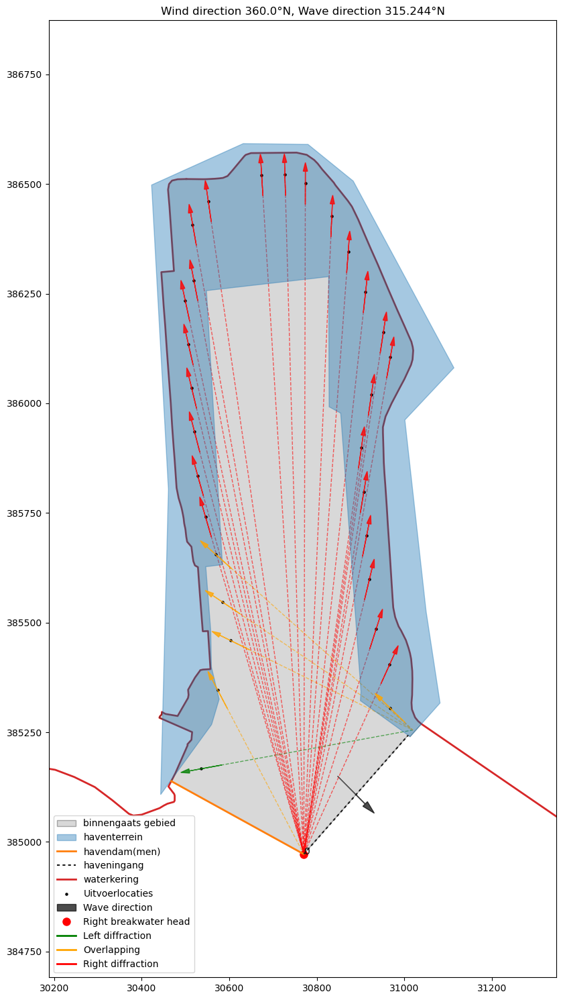

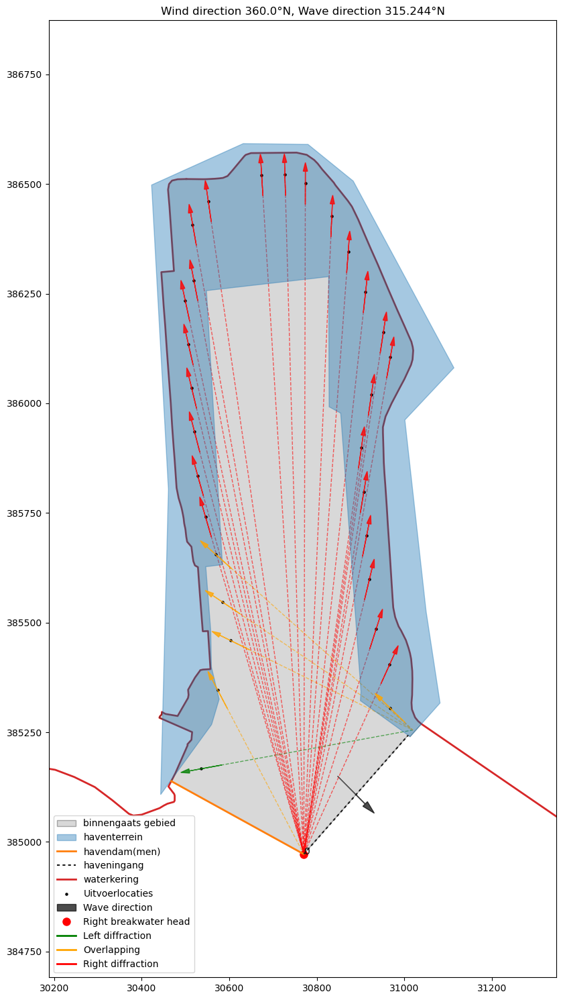

...

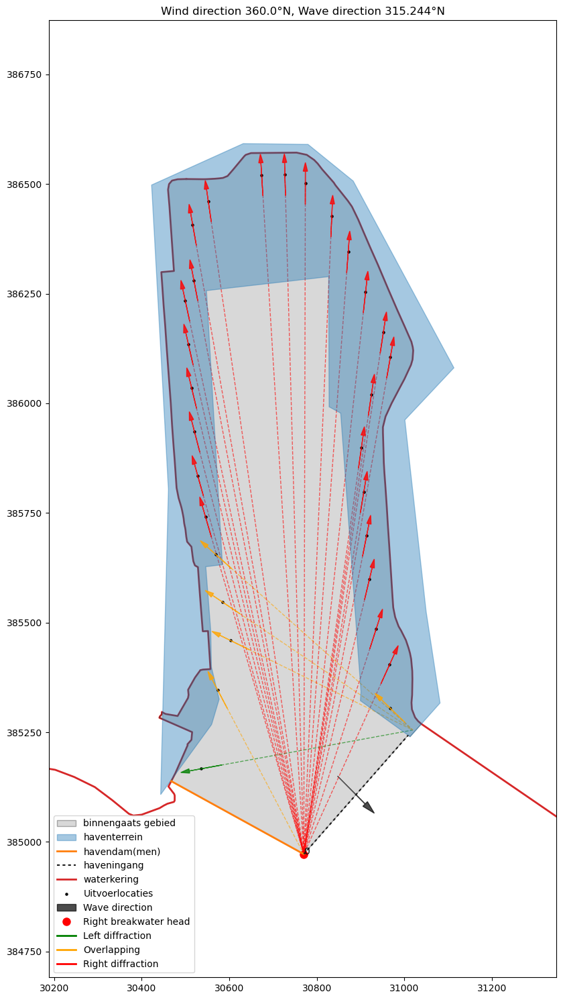

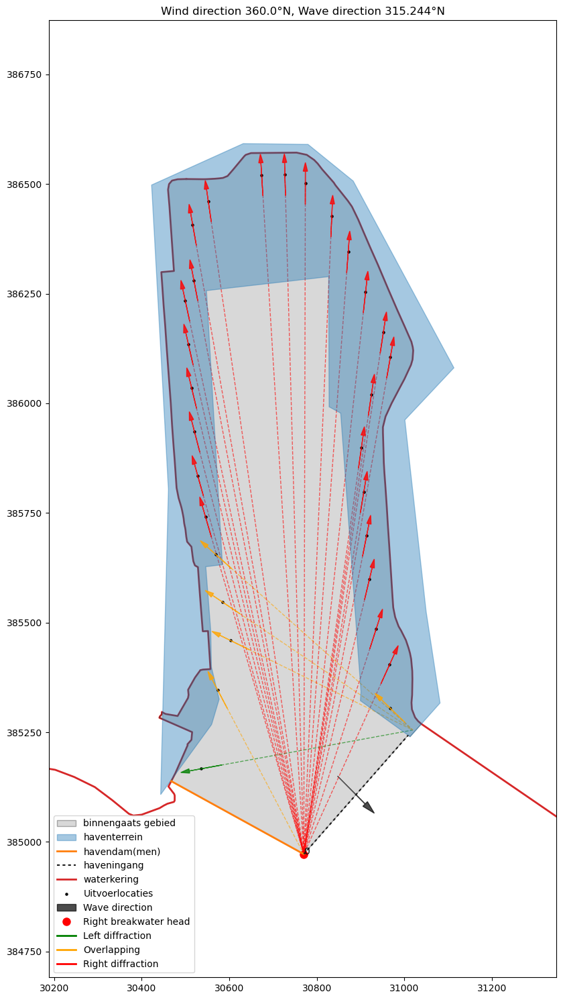

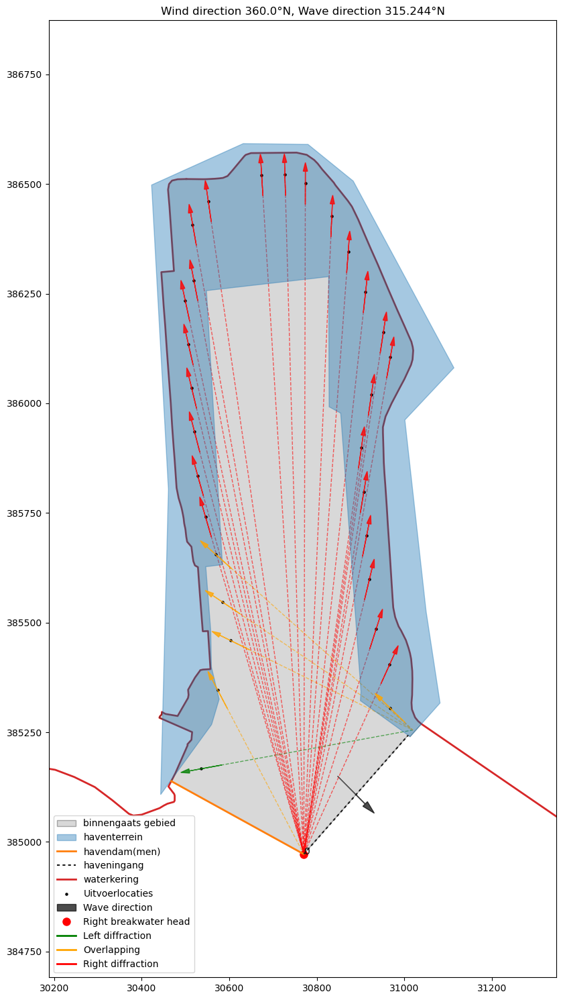

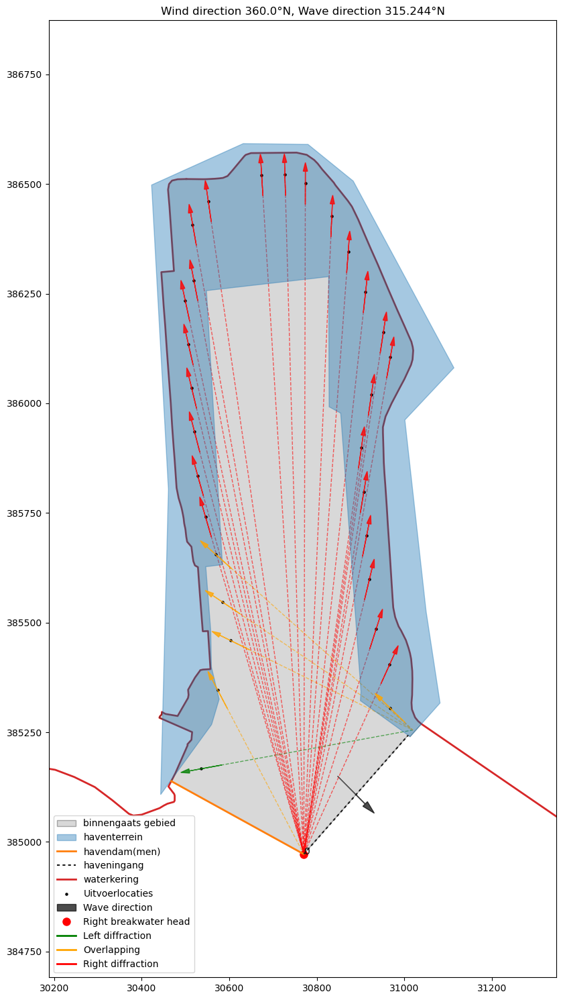

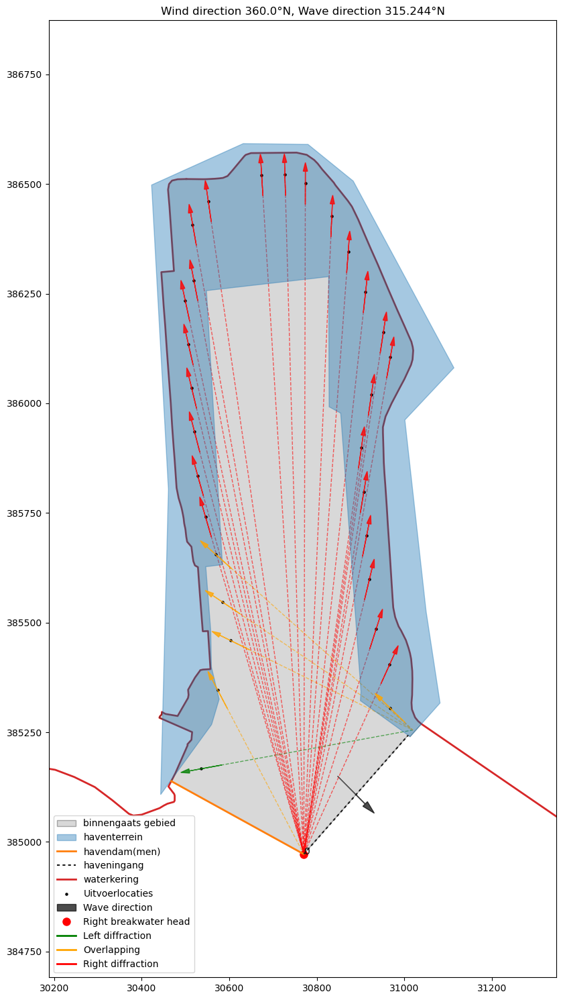

In [17]:
plot_diffraction_results(model, hlid)

## Test Case 3: Urk

Different geometric arrangement for testing various diffraction scenarios.

In [18]:
case = 'urk'
casedir = os.path.join(tempdir,case)
if os.path.isdir(casedir):
    shutil.rmtree(casedir)

datadir = os.path.join(trunkdir, 'tests', 'data')
paths = {
    'harborarea': os.path.join(datadir, case, 'shapes', 'haventerrein.shp'),
    'breakwater': os.path.join(datadir, case, 'shapes', 'havendammen.shp'),
    'result_locations': os.path.join(datadir, case, 'shapes', 'uitvoerlocaties.shp'),
    'hrd': os.path.join(datadir, case, 'databases', 'WBI2017_IJsselmeer_7-2_v02_steunpunt.sqlite'),
    'config': os.path.join(datadir, case, 'databases', 'WBI2017_IJsselmeer_7-2_v02_steunpunt.config.sqlite'),
    'hlcd': os.path.join(datadir, 'hlcd.sqlite'),
}
trajecten = ['7-2']
bedlevel = -5.0
supportlocation = 'YM_3_7-2_ha02_00001'

In [19]:
model = MainModel()
model.project.settings['project']['name'] = case
model.project.settings['project']['user']['email'] = 'benit@hkv.nl'
model.project.settings['project']['user']['name'] = 'Matthijs Bénit'

model.project.save_as(os.path.join(tempdir, case + '.json'))

common.add_schematisation(model, paths=paths, supportlocationname=supportlocation, trajecten=trajecten, bedlevel=bedlevel)

model.simple_calculation.run_all(['Lokale golfgroei', 'Transmissie', 'Diffractie', 'Golfbreking'])
model.simple_calculation.combinedresults.run(['Lokale golfgroei', 'Diffractie', 'Transmissie', 'Golfbreking'])
model.simple_calculation.mainmodel.project.settings['simple']['finished'] = True
model.simple_calculation.save_results()

# Save results
model.project.save()
model.save_tables()

OSError: Cannot save file into a non-existent directory: 'c:\Users\Benit\HB Havens R489\temp\urk'

In [ ]:
hlid = [model.hydraulic_loads.loc[
    (model.hydraulic_loads['ClosingSituationId'] == 1) &
    (model.hydraulic_loads['Wind speed'] == 34.) &
    (model.hydraulic_loads['Water level IJssel lake'] == 1.8) 
    ].index[-1] for wd in model.hydraulic_loads.loc[:,'Wind direction'].unique()]
model.hydraulic_loads.loc[hlid]

,ClosingSituationId,Wind direction,Water level IJssel lake,Wind speed,h,Hs,Tp,"Tm-1,0",Wave direction,Description
HydraulicLoadId,,,,,,,,,,
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34
37148,1,360.0,1.8,34.0,2.555,1.091,2.89,2.7141,341.25,D=360.0 M=1.80 U=34


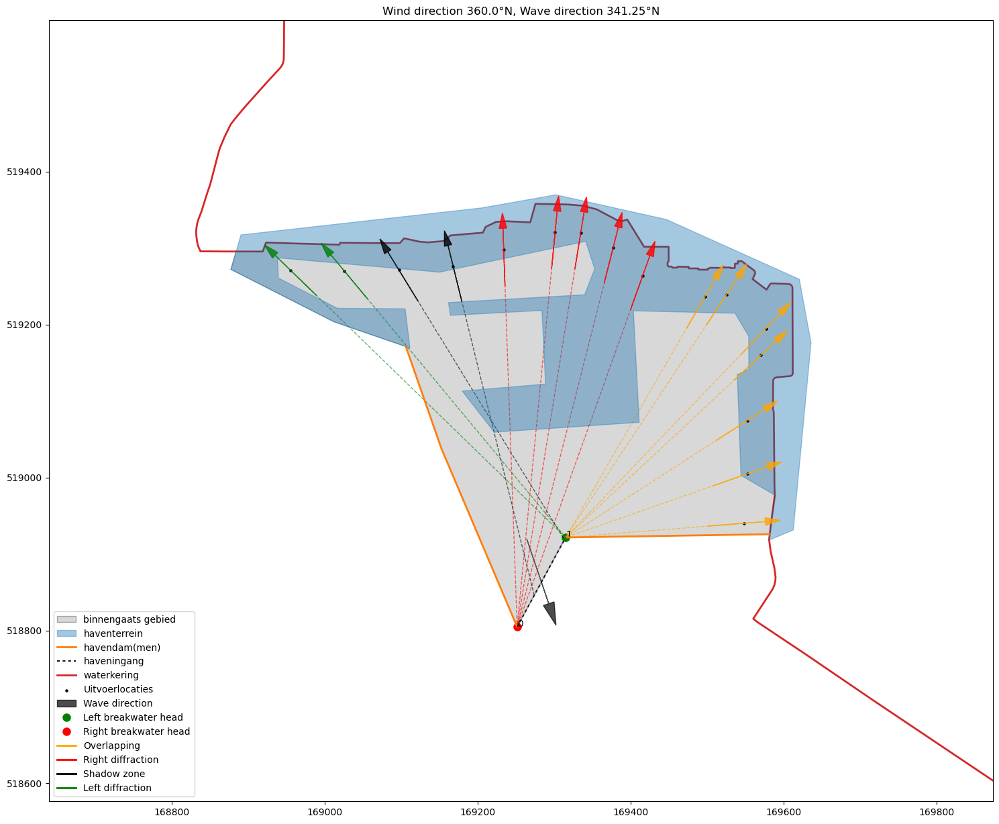

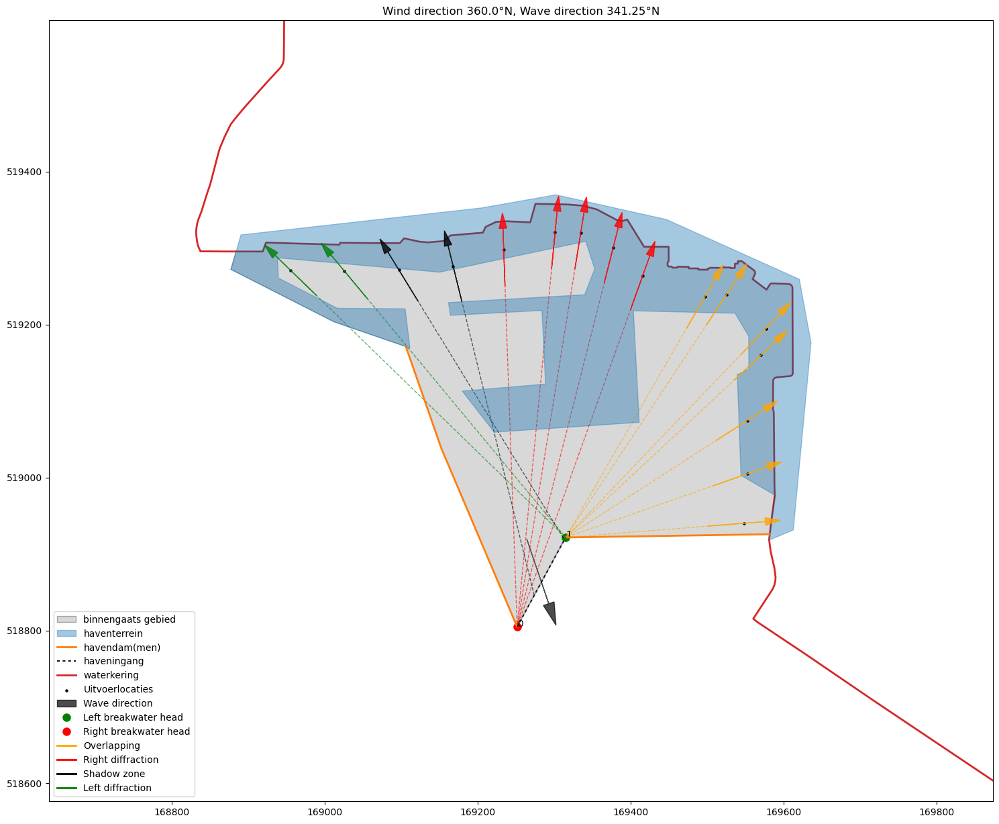

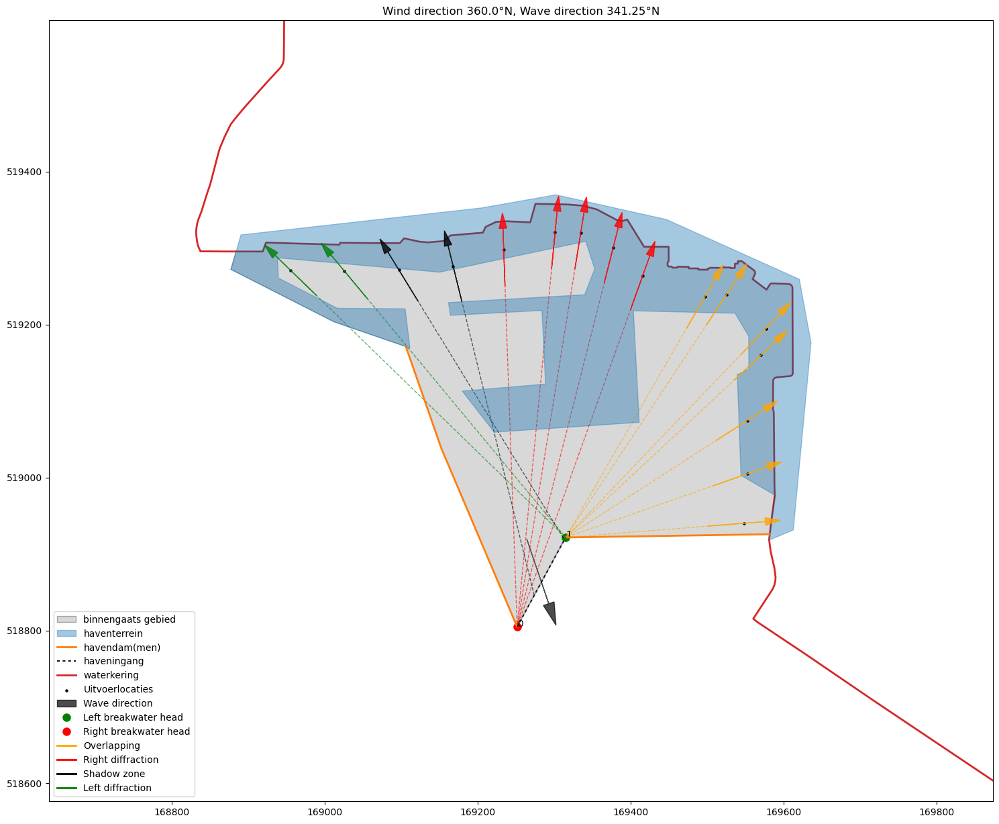

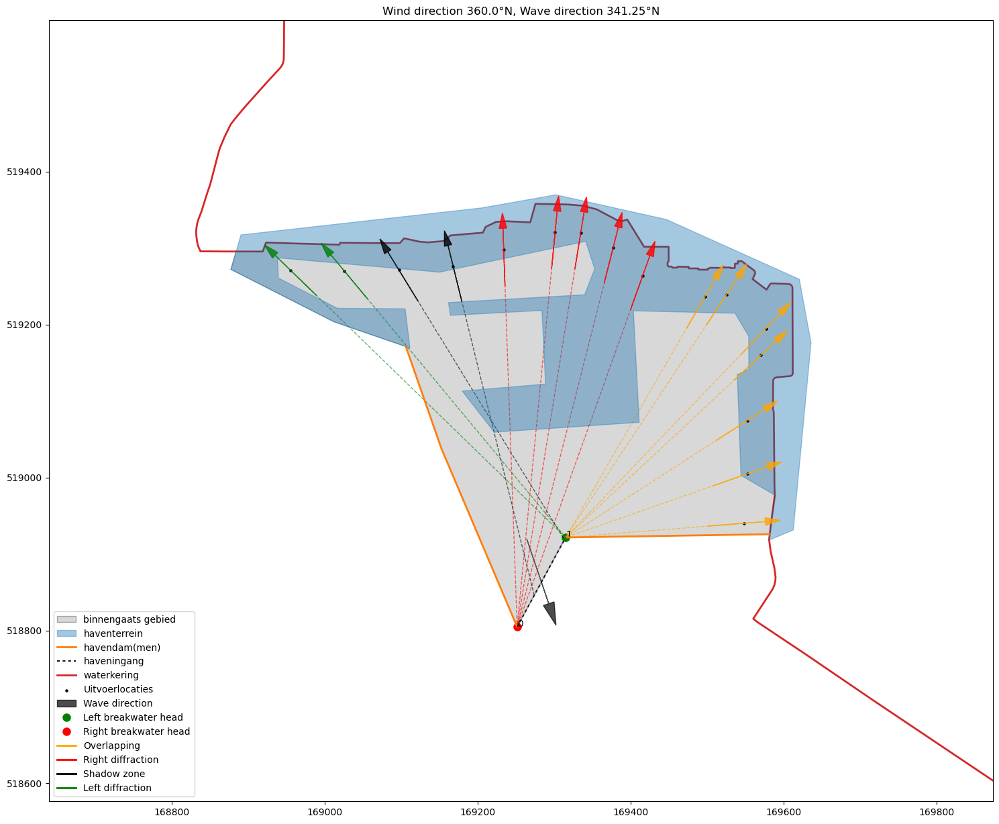

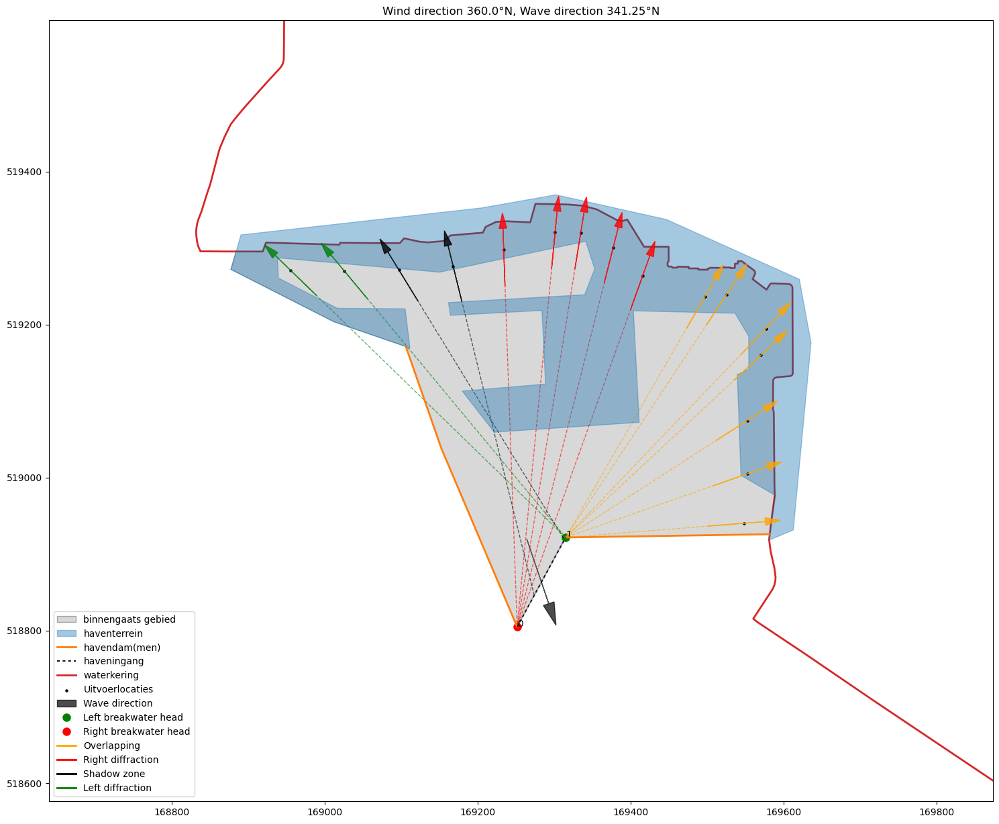

...

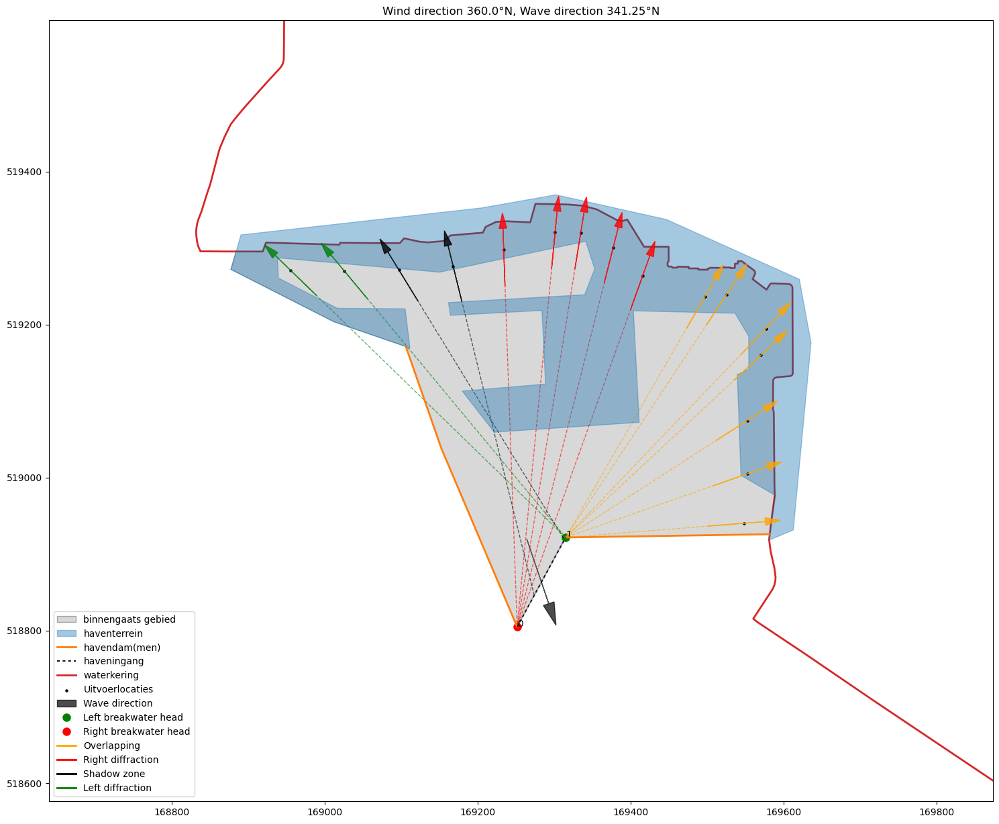

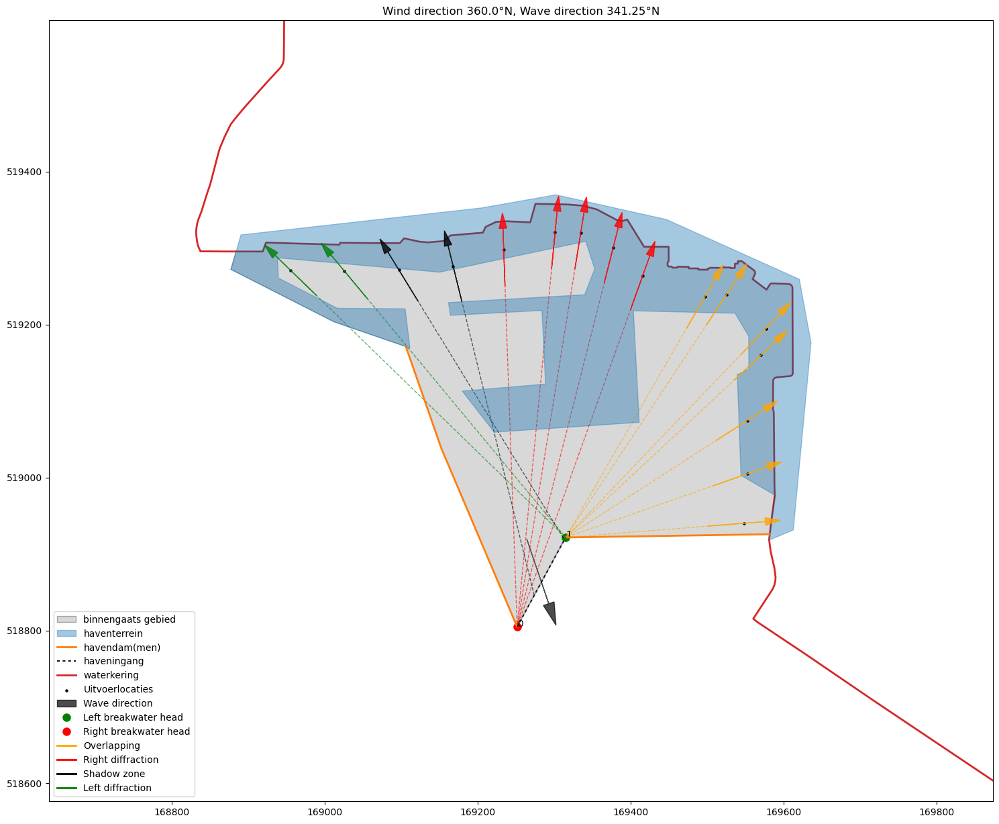

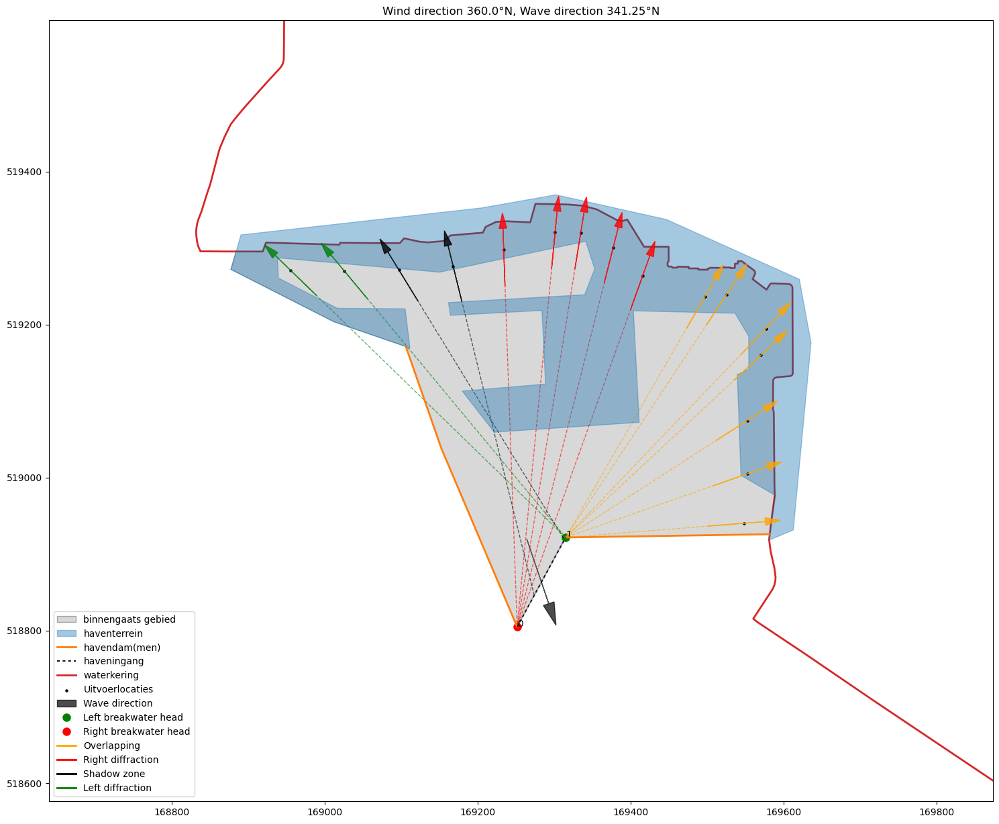

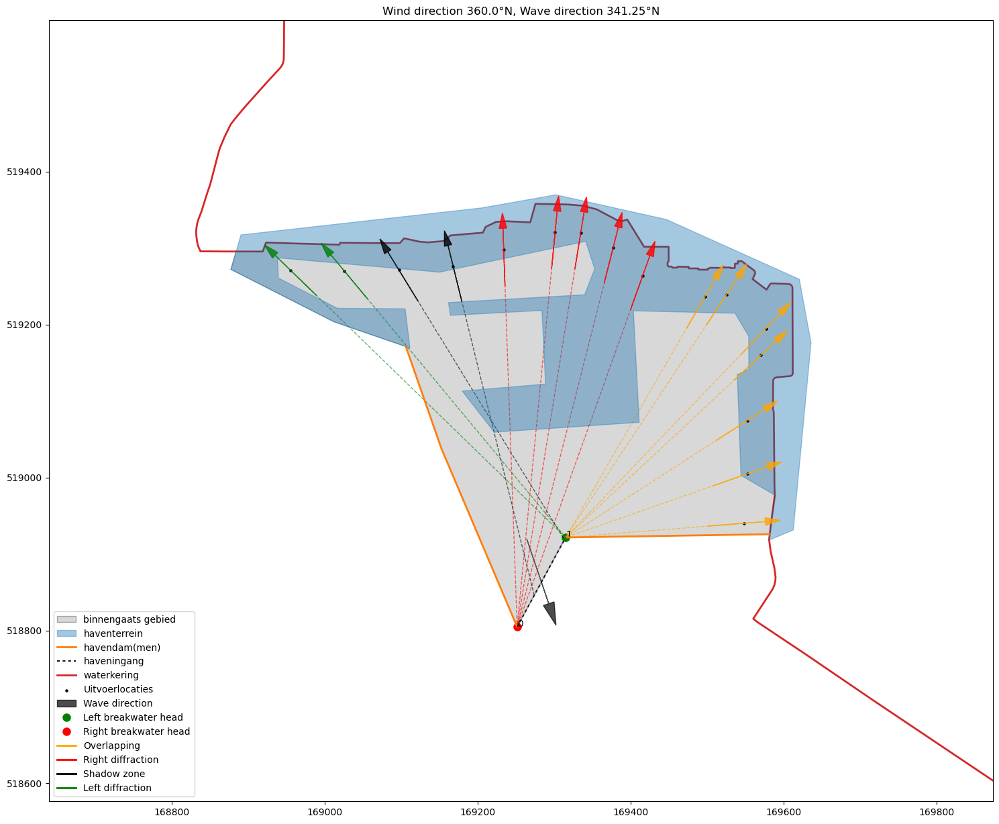

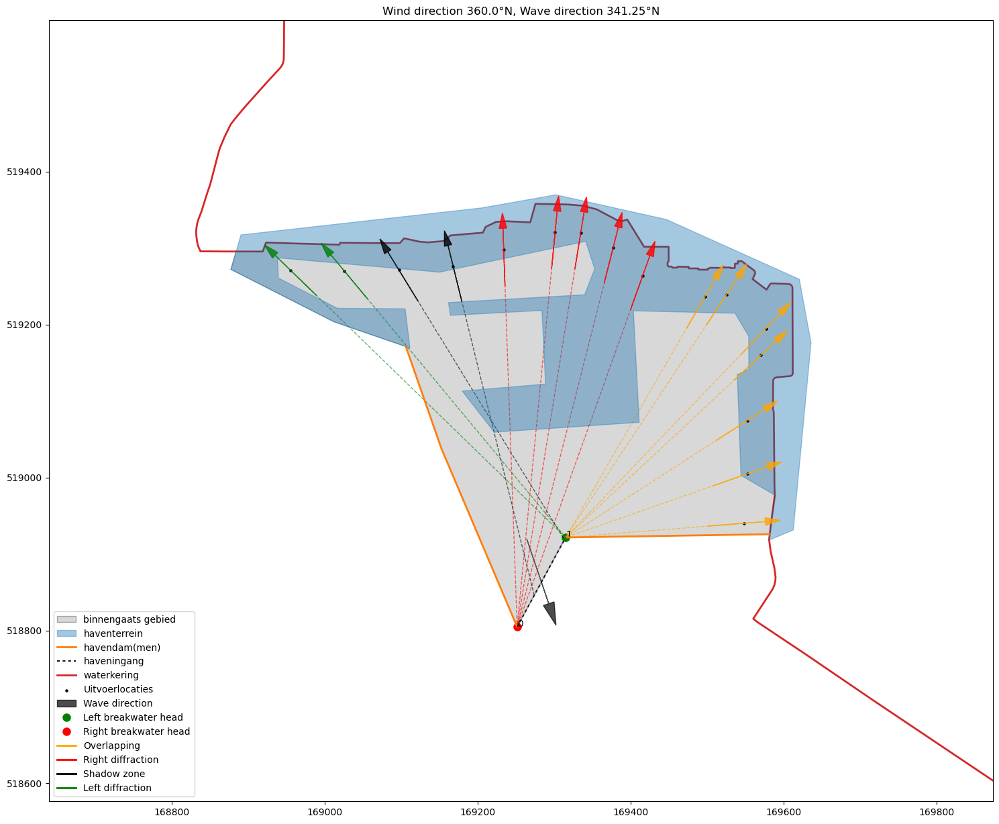

In [ ]:
plot_diffraction_results(model, hlid)

## Test Case 4a: Vluchthaven

First variation including original diffraction point.

In [ ]:
case = 'vluchthaven'
casedir = os.path.join(tempdir,case)
if os.path.isdir(casedir):
    shutil.rmtree(casedir)

datadir = os.path.join(trunkdir, 'tests', 'data', case)
paths = {
    'harborarea': os.path.join(datadir, 'shapes', 'haventerrein.shp'),
    'breakwater': os.path.join(datadir, 'shapes', 'havendam.shp'),
    'result_locations': os.path.join(datadir, 'shapes', 'uitvoerlocaties.shp'),
    'hrd': os.path.join(datadir, 'databases', 'WBI2017_Bovenrijn_43-6_v04_steunpunt.sqlite'),
    'config': os.path.join(datadir, 'databases', 'WBI2017_Bovenrijn_43-6_v04_steunpunt.config.sqlite'),
    'hlcd': os.path.join(datadir, '..', 'hlcd_nieuw.sqlite'),
}
trajecten = ['43-6']
bedlevel = 0.0
supportlocation = '043-06_0023_1_WA_km0914'
entrance = (158800.0, 433050.0)


In [ ]:
model = MainModel()
model.project.settings['project']['name'] = case
model.project.settings['project']['user']['email'] = 'benit@hkv.nl'
model.project.settings['project']['user']['name'] = 'Matthijs Bénit'

model.project.save_as(os.path.join(tempdir, case + '.json'))

common.add_schematisation(model, paths=paths, supportlocationname=supportlocation, trajecten=trajecten, bedlevel=bedlevel, entrance_coordinate=entrance)

model.simple_calculation.run_all(['Lokale golfgroei', 'Transmissie', 'Diffractie', 'Golfbreking'])
model.simple_calculation.combinedresults.run(['Lokale golfgroei', 'Diffractie', 'Transmissie', 'Golfbreking'])
model.simple_calculation.mainmodel.project.settings['simple']['finished'] = True
model.simple_calculation.save_results()

# Save results
model.project.save()
model.save_tables()

In [ ]:
hlid = [model.hydraulic_loads.loc[
    (model.hydraulic_loads['ClosingSituationId'] == 1) &
    (model.hydraulic_loads['Wind speed'] == 30.) &
    (model.hydraulic_loads['Discharge Lobith'] == 24000) 
    ].index[-1] for wd in model.hydraulic_loads.loc[:,'Wind direction'].unique()]
model.hydraulic_loads.loc[hlid]

,ClosingSituationId,Wind direction,Discharge Lobith,Wind speed,h,Hs,Tp,"Tm-1,0",Wave direction,Description
HydraulicLoadId,,,,,,,,,,
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30


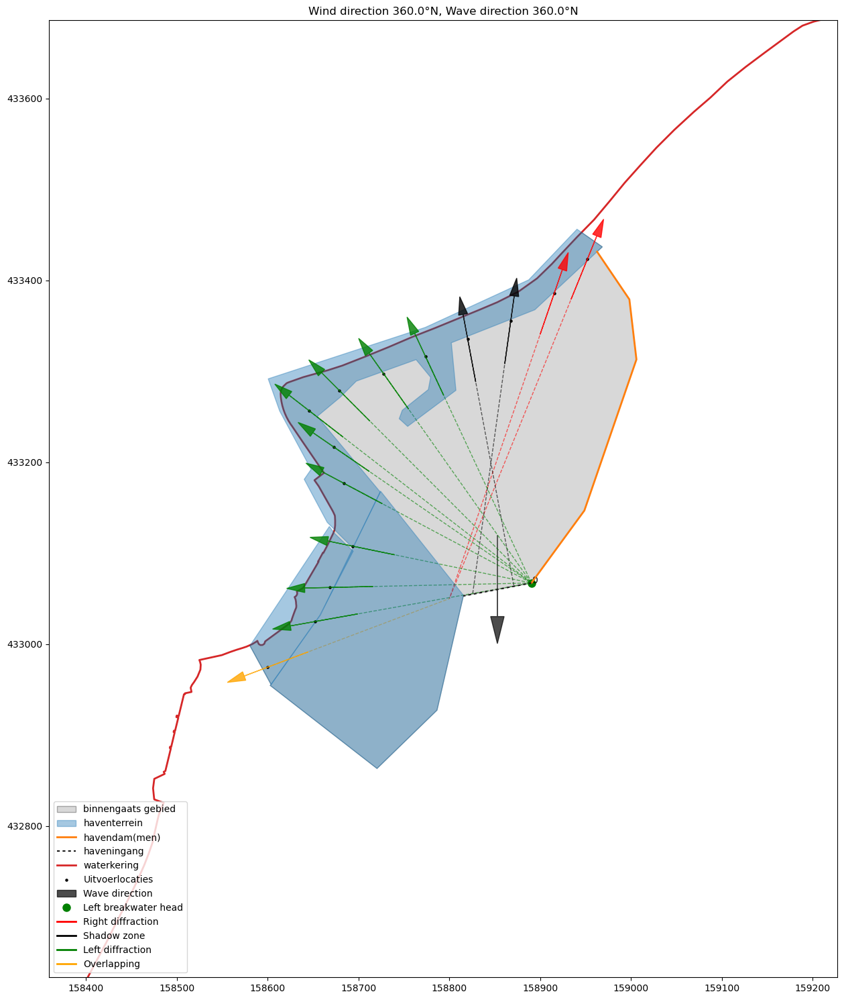

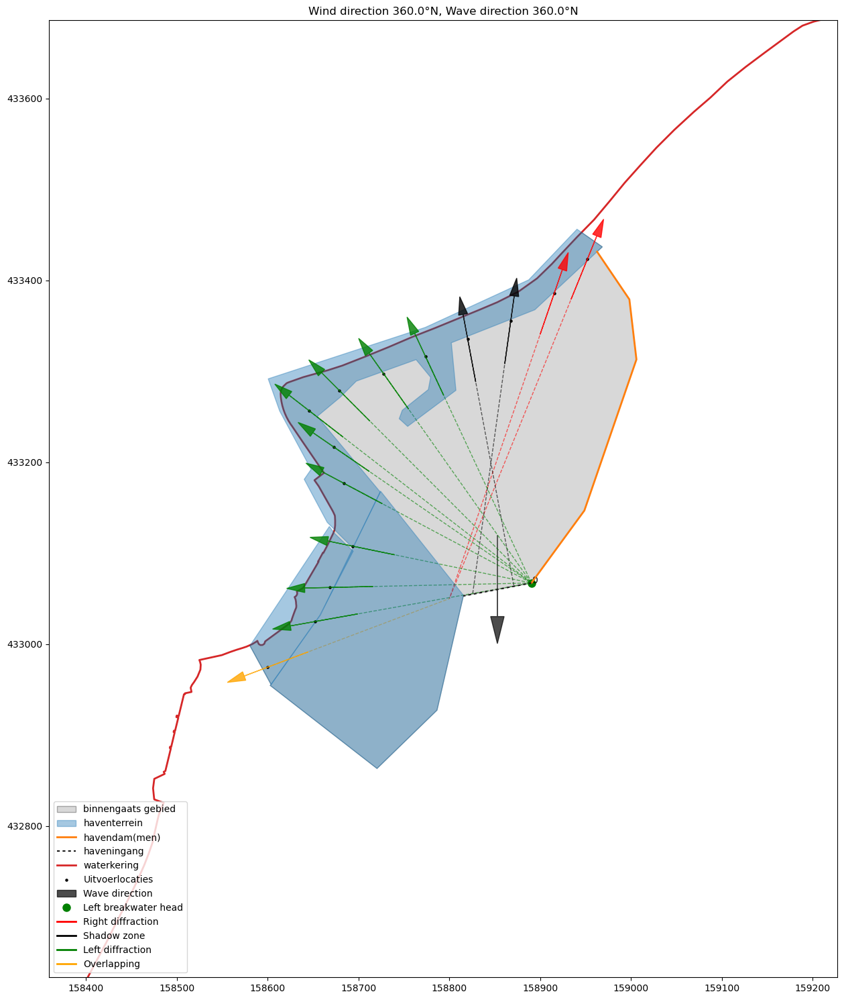

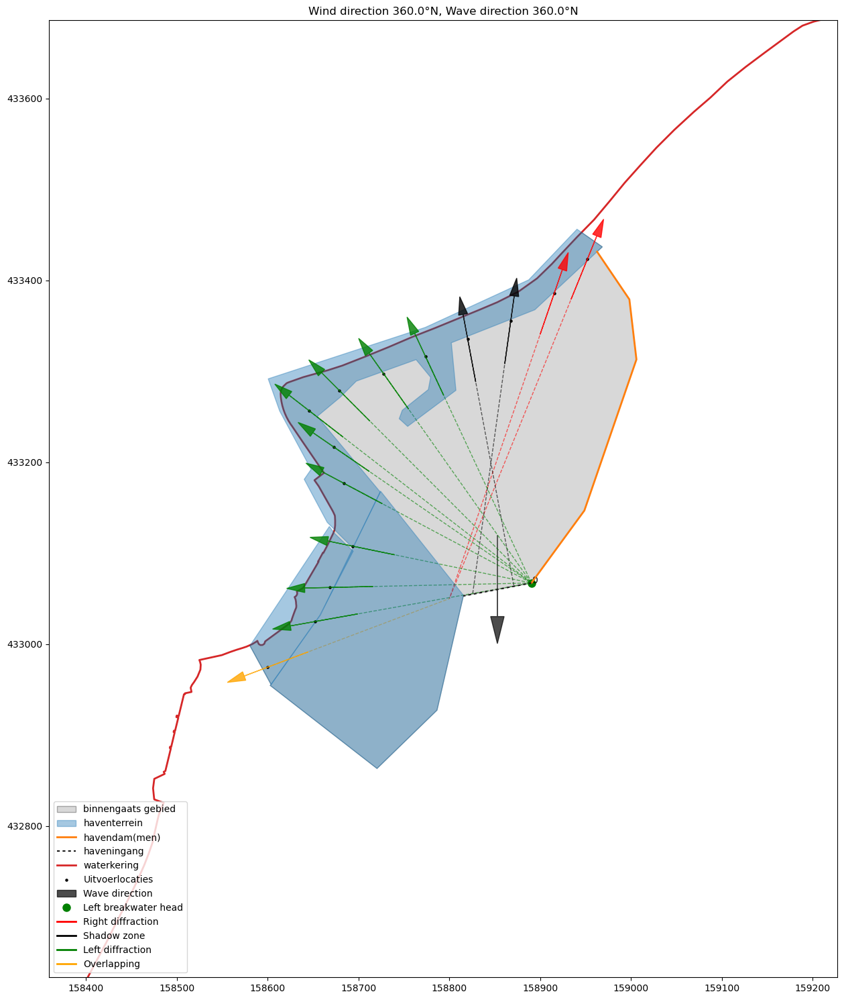

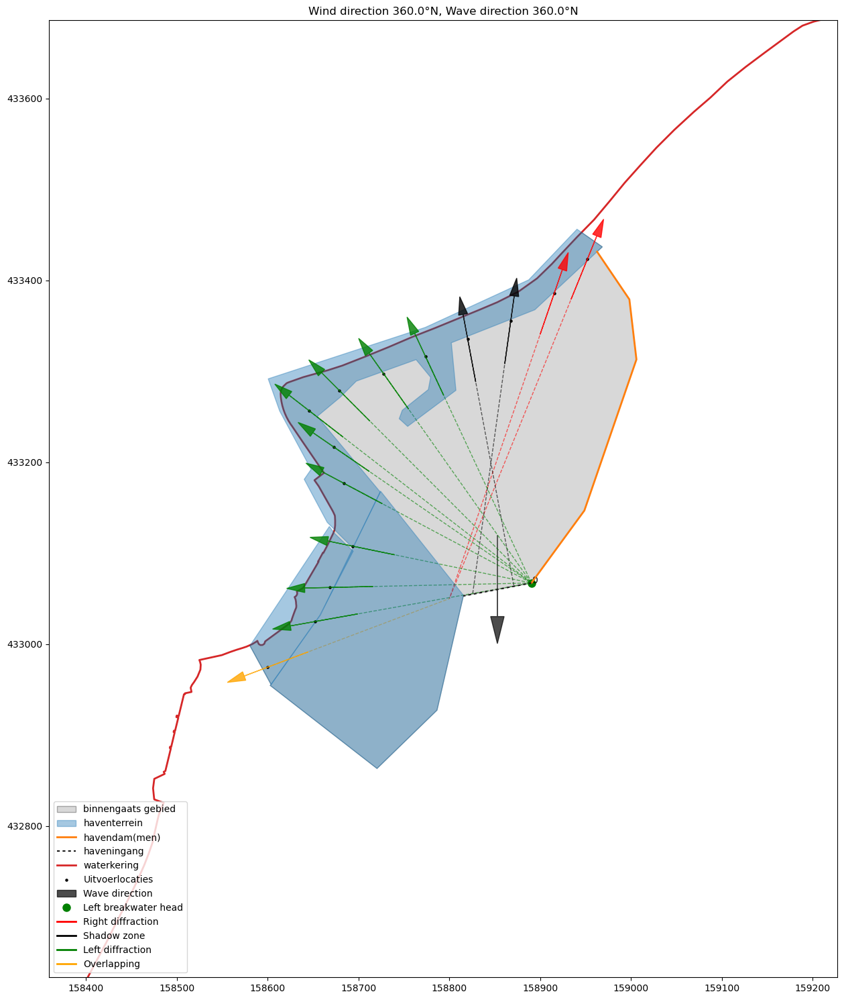

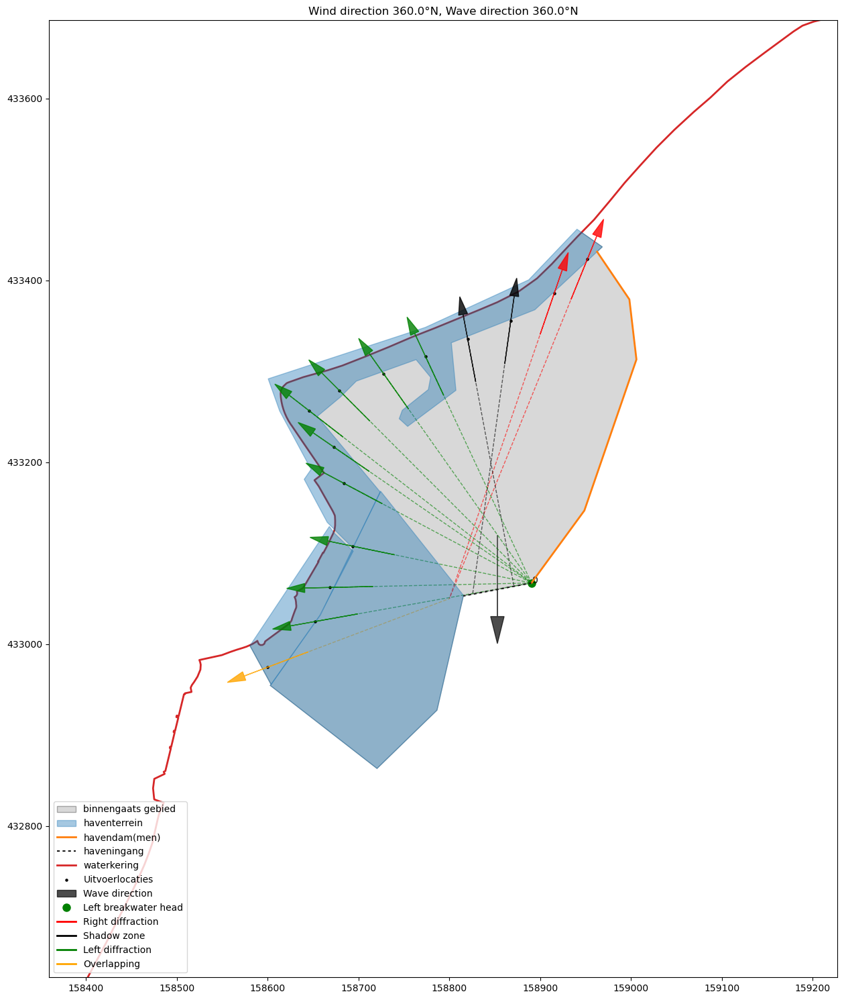

...

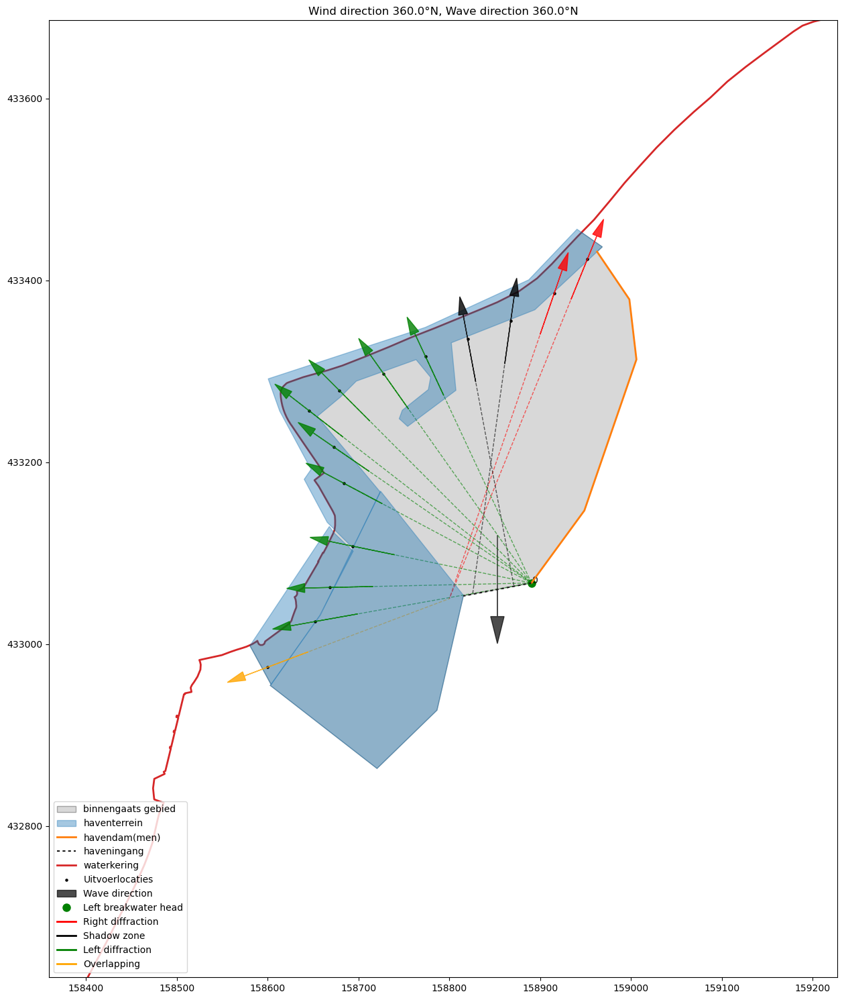

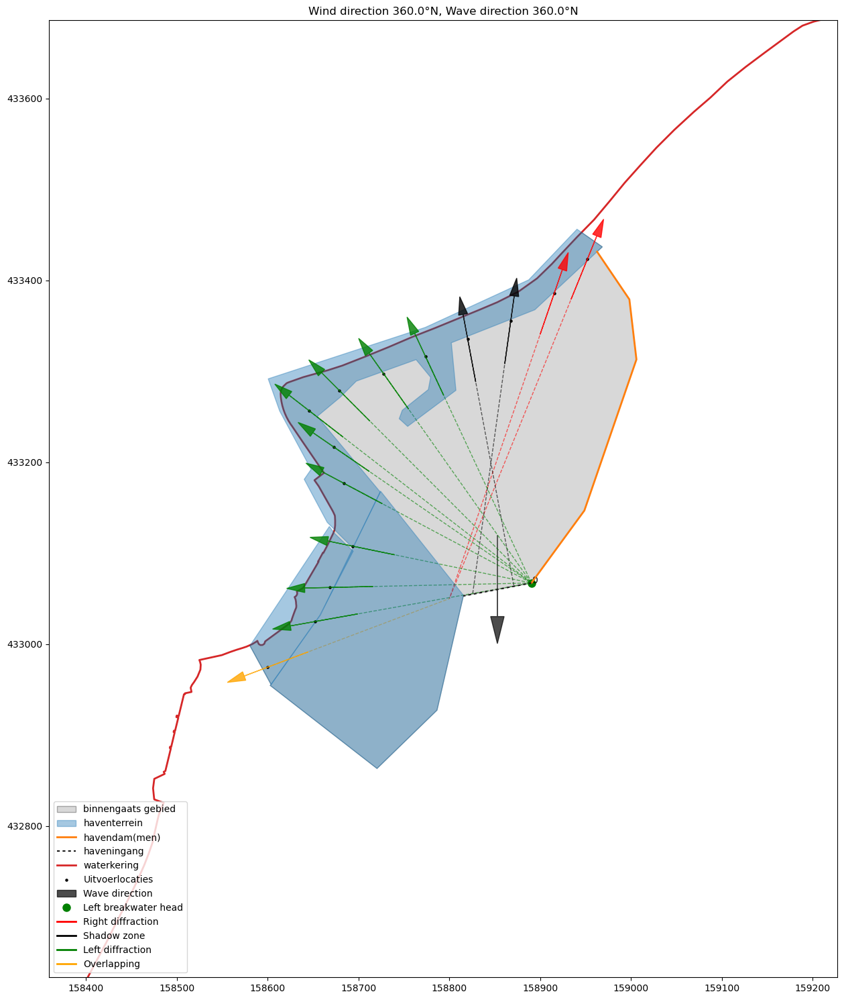

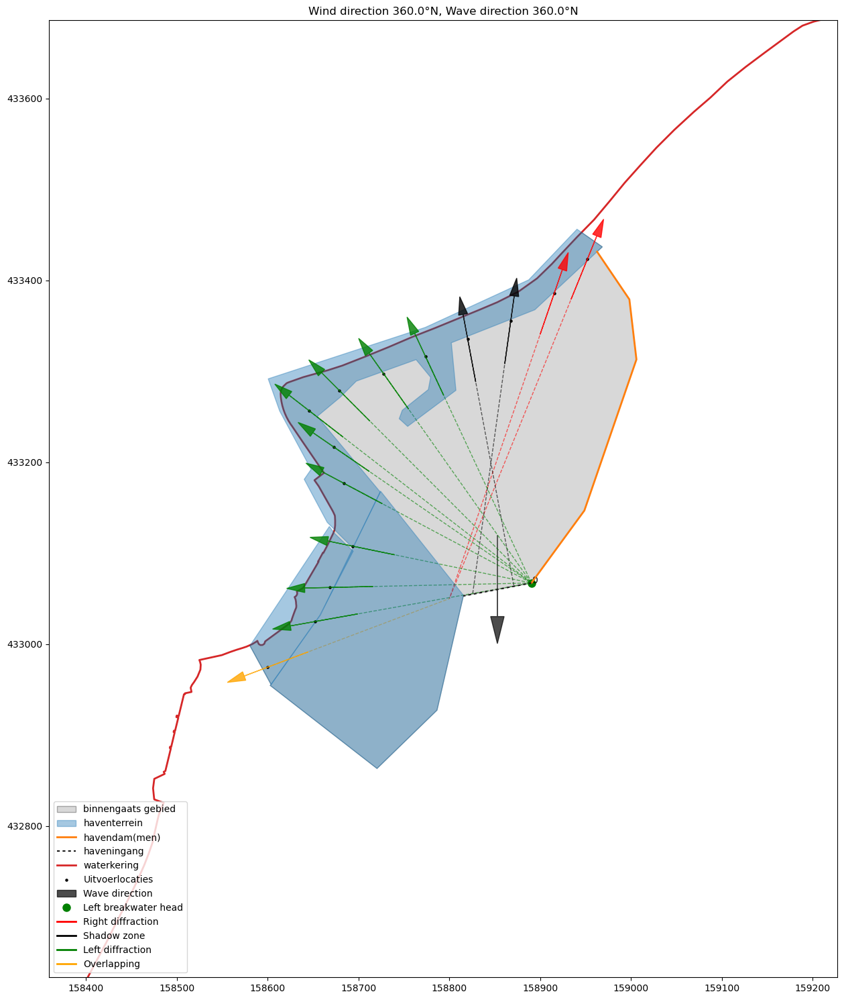

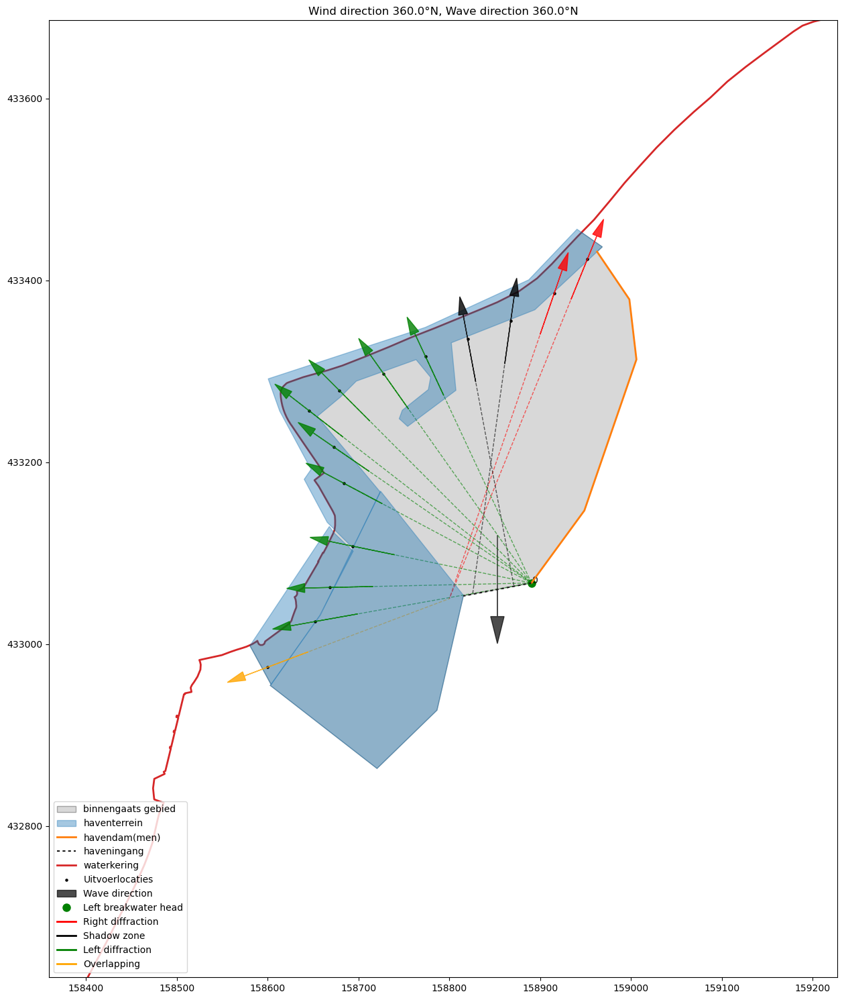

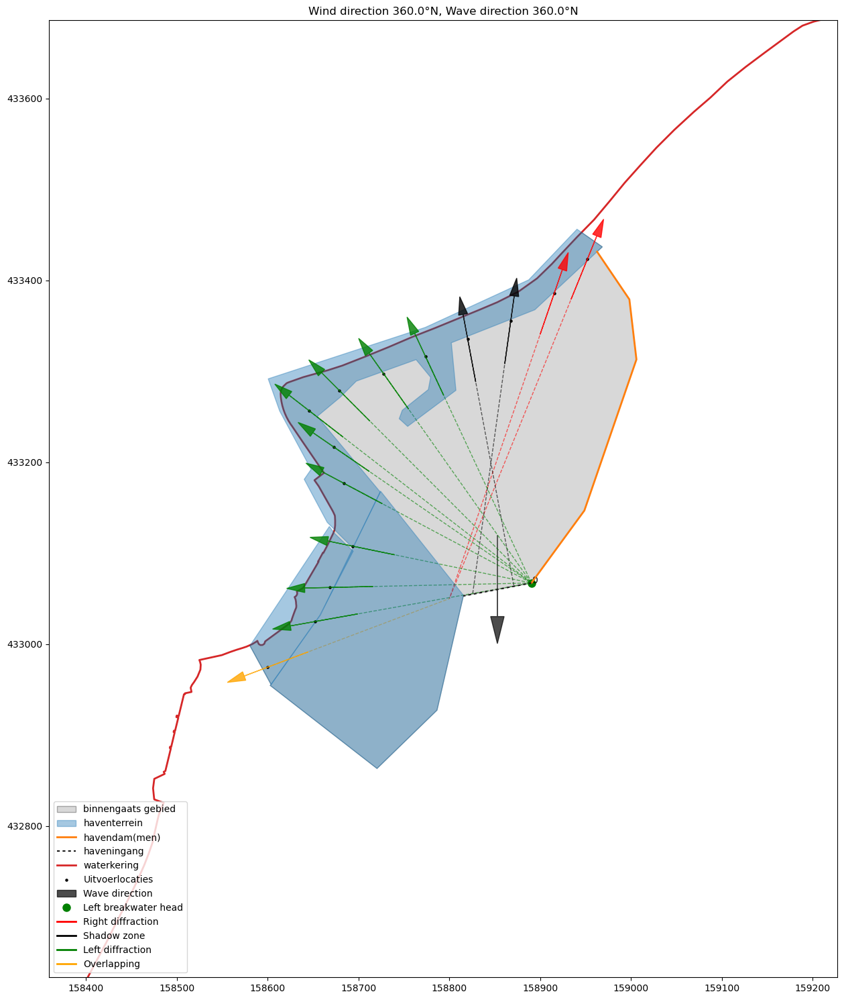

In [ ]:
plot_diffraction_results(model, hlid)

## Test Case 4b: Vluchthaven

Second variation including repositioned diffraction point.

In [ ]:
case = 'vluchthaven'
casedir = os.path.join(tempdir,case)
if os.path.isdir(casedir):
    shutil.rmtree(casedir)

datadir = os.path.join(trunkdir, 'tests', 'data', case)
paths = {
    'harborarea': os.path.join(datadir, 'shapes', 'haventerrein.shp'),
    'breakwater': os.path.join(datadir, 'shapes', 'havendam.shp'),
    'result_locations': os.path.join(datadir, 'shapes', 'uitvoerlocaties.shp'),
    'hrd': os.path.join(datadir, 'databases', 'WBI2017_Bovenrijn_43-6_v04_steunpunt.sqlite'),
    'config': os.path.join(datadir, 'databases', 'WBI2017_Bovenrijn_43-6_v04_steunpunt.config.sqlite'),
    'hlcd': os.path.join(datadir, '..', 'hlcd_nieuw.sqlite'),
}
trajecten = ['43-6']
bedlevel = 0.0
supportlocation = '043-06_0023_1_WA_km0914'
entrance = (158700.0, 432900.0)


In [ ]:
model = MainModel()
model.project.settings['project']['name'] = case
model.project.settings['project']['user']['email'] = 'benit@hkv.nl'
model.project.settings['project']['user']['name'] = 'Matthijs Bénit'

model.project.save_as(os.path.join(tempdir, case + '.json'))

common.add_schematisation(model, paths=paths, supportlocationname=supportlocation, trajecten=trajecten, bedlevel=bedlevel, entrance_coordinate=entrance)

model.simple_calculation.run_all(['Lokale golfgroei', 'Transmissie', 'Diffractie', 'Golfbreking'])
model.simple_calculation.combinedresults.run(['Lokale golfgroei', 'Diffractie', 'Transmissie', 'Golfbreking'])
model.simple_calculation.mainmodel.project.settings['simple']['finished'] = True
model.simple_calculation.save_results()

# Save results
model.project.save()
model.save_tables()

In [ ]:
hlid = [model.hydraulic_loads.loc[
    (model.hydraulic_loads['ClosingSituationId'] == 1) &
    (model.hydraulic_loads['Wind speed'] == 30.) &
    (model.hydraulic_loads['Discharge Lobith'] == 24000) 
    ].index[-1] for wd in model.hydraulic_loads.loc[:,'Wind direction'].unique()]
model.hydraulic_loads.loc[hlid]

,ClosingSituationId,Wind direction,Discharge Lobith,Wind speed,h,Hs,Tp,"Tm-1,0",Wave direction,Description
HydraulicLoadId,,,,,,,,,,
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30
33376,1,360.0,24000.0,30.0,13.077678,0.460668,2.294451,2.085865,360.0,D=360.0 Q=24000 U=30


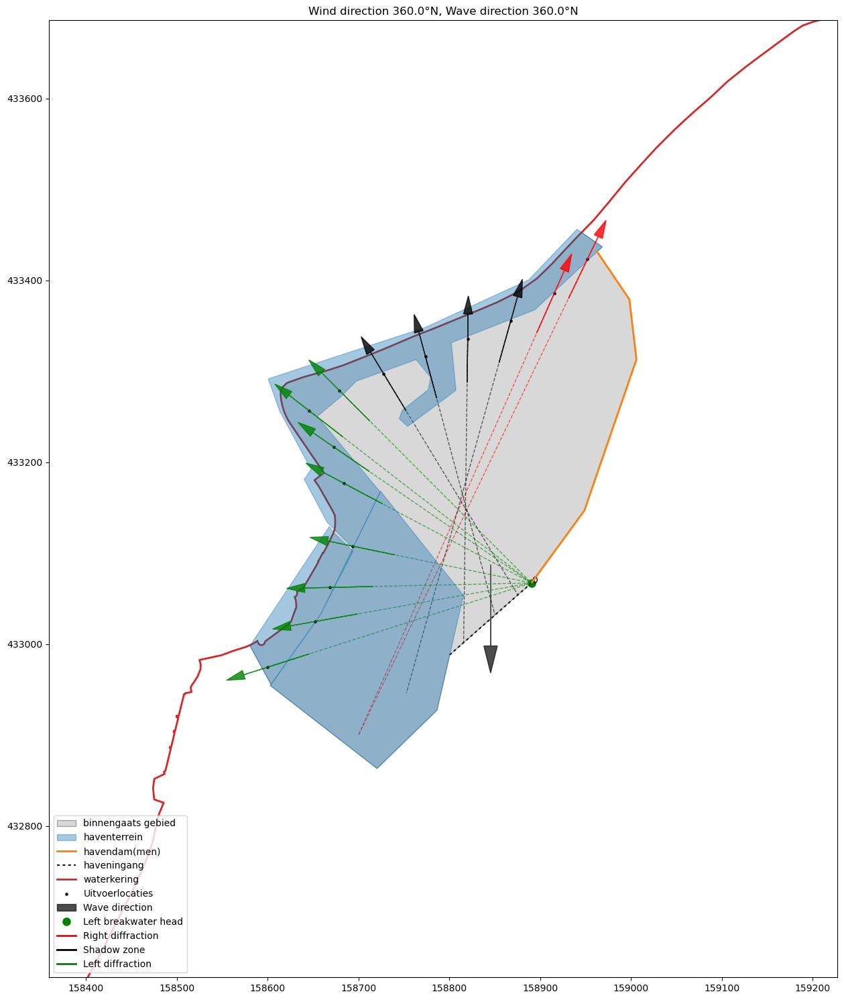

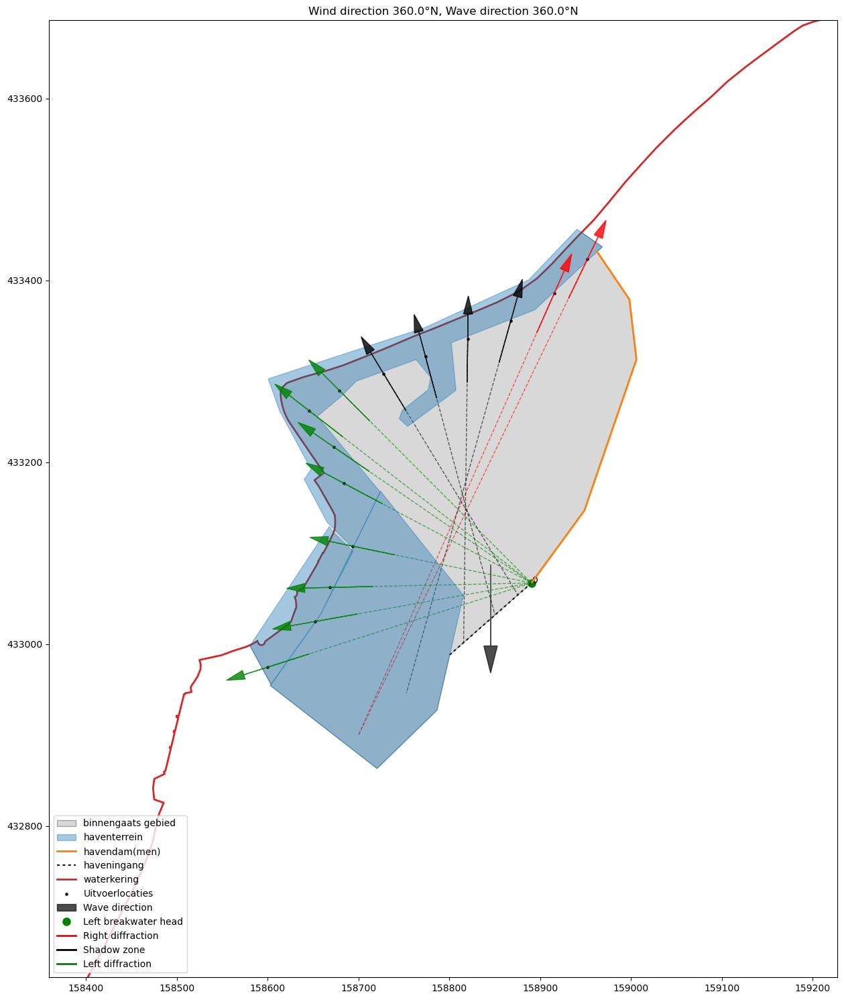

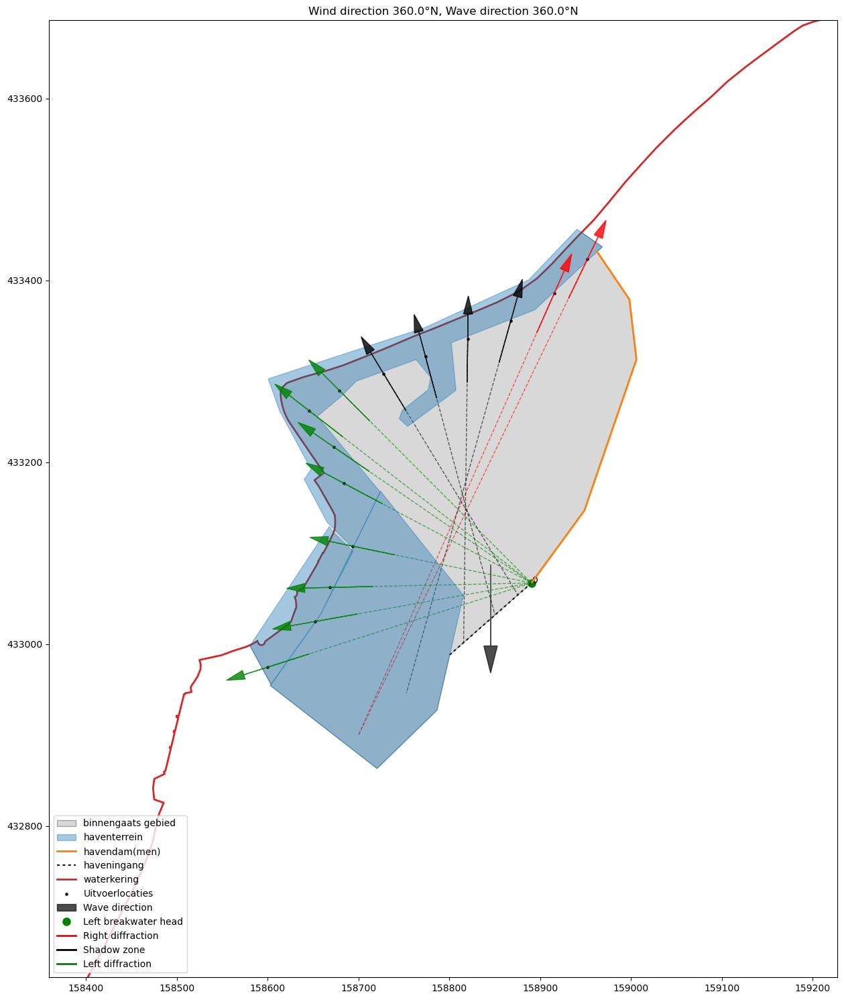

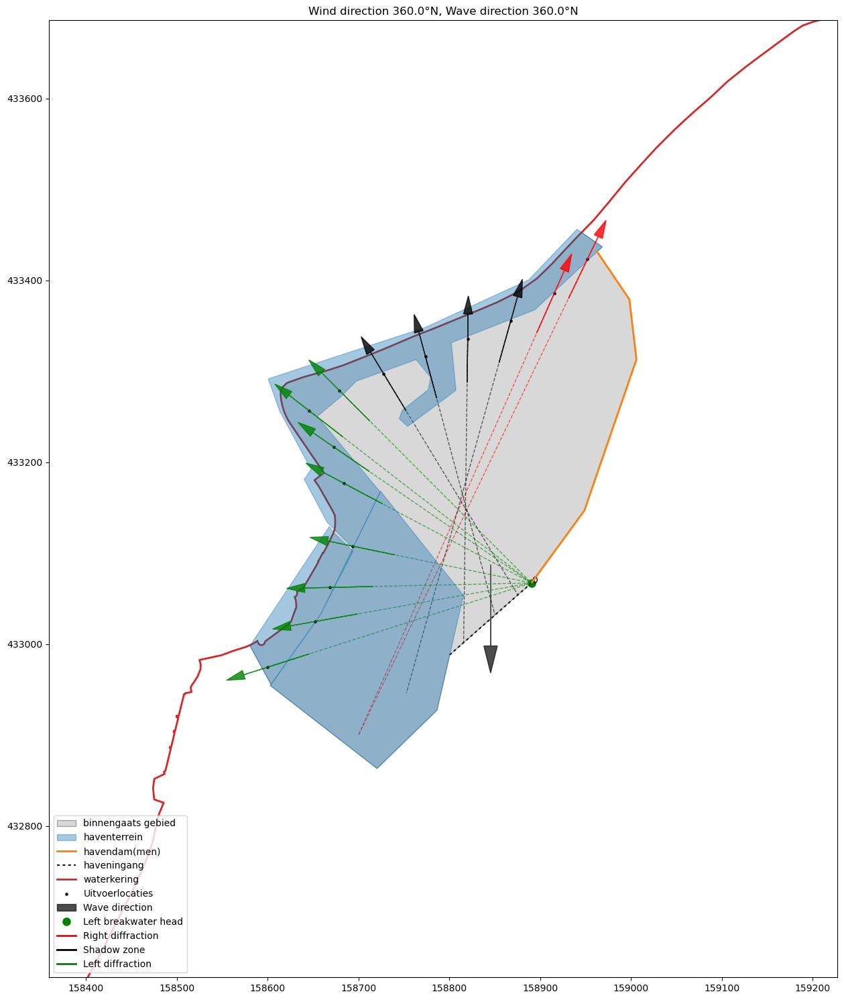

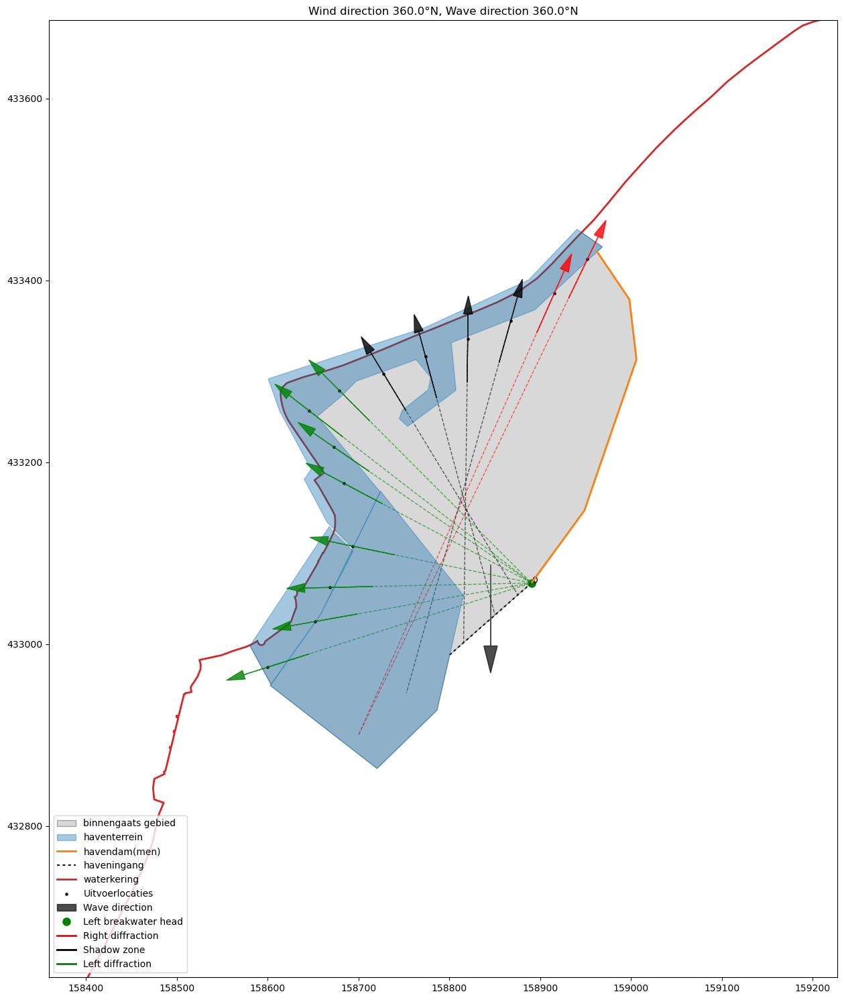

...

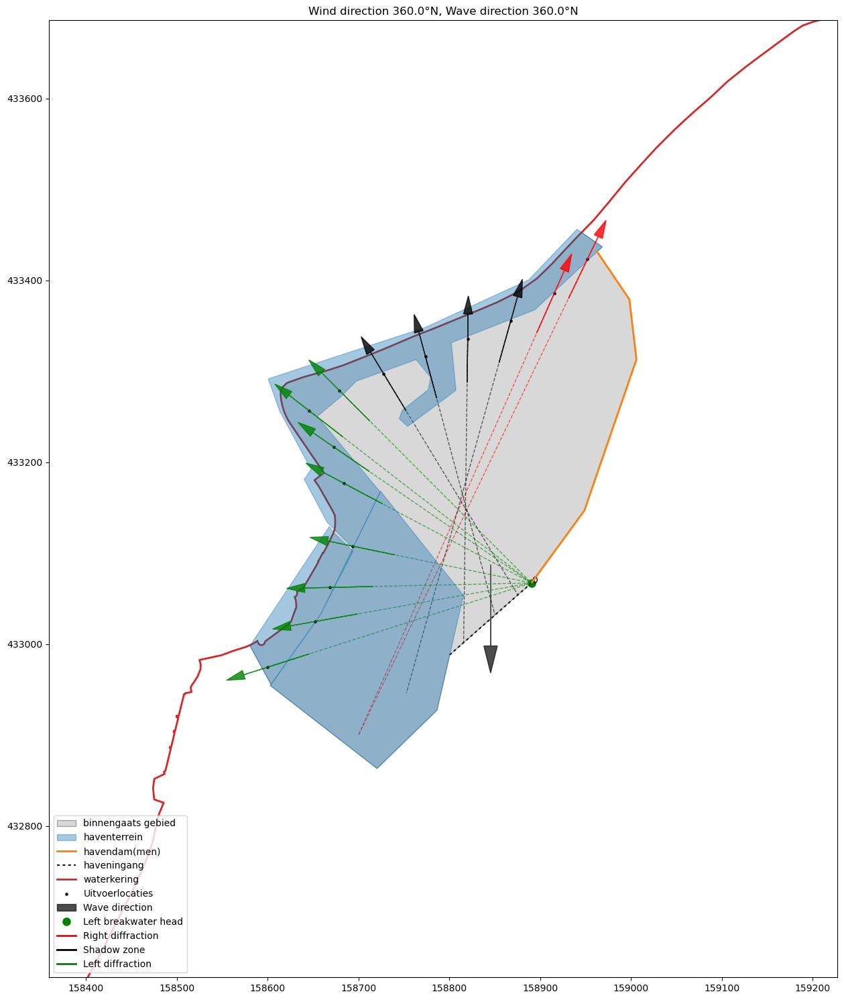

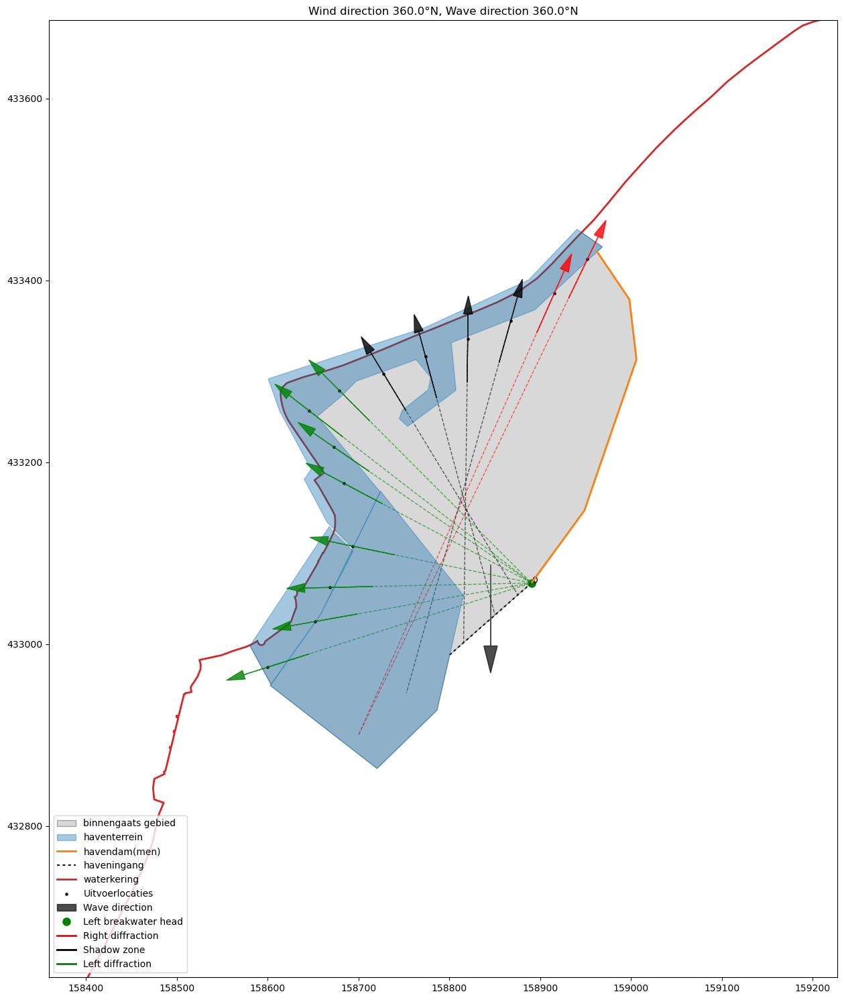

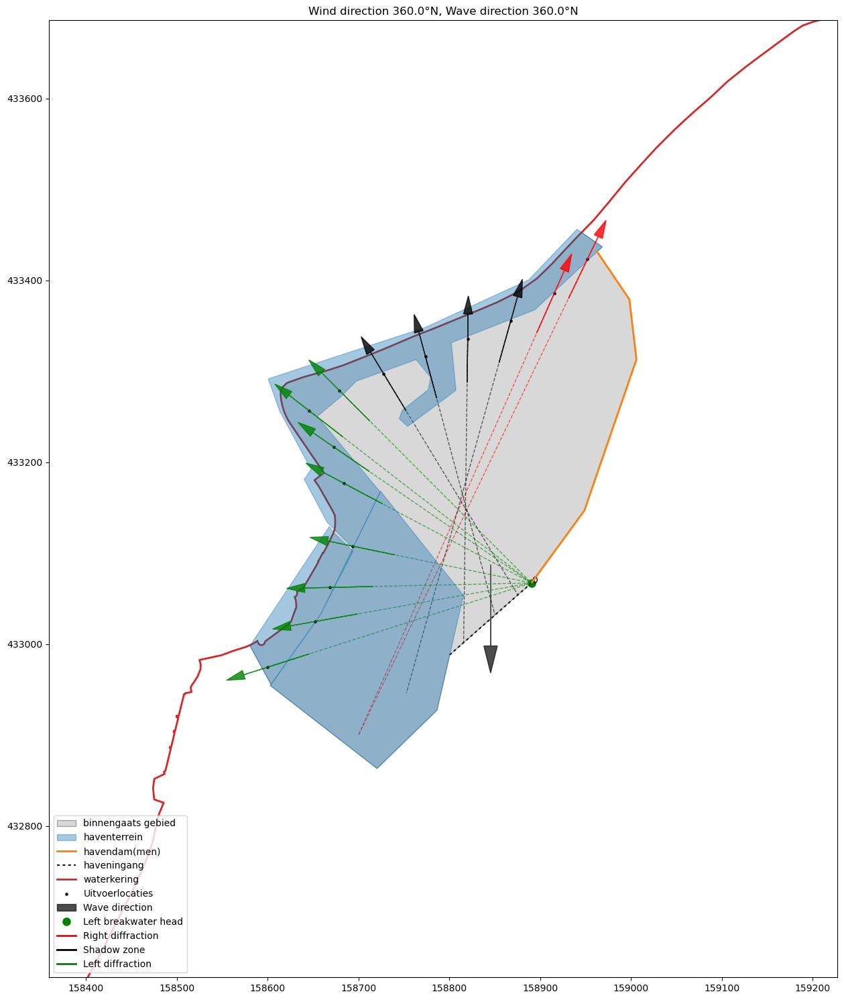

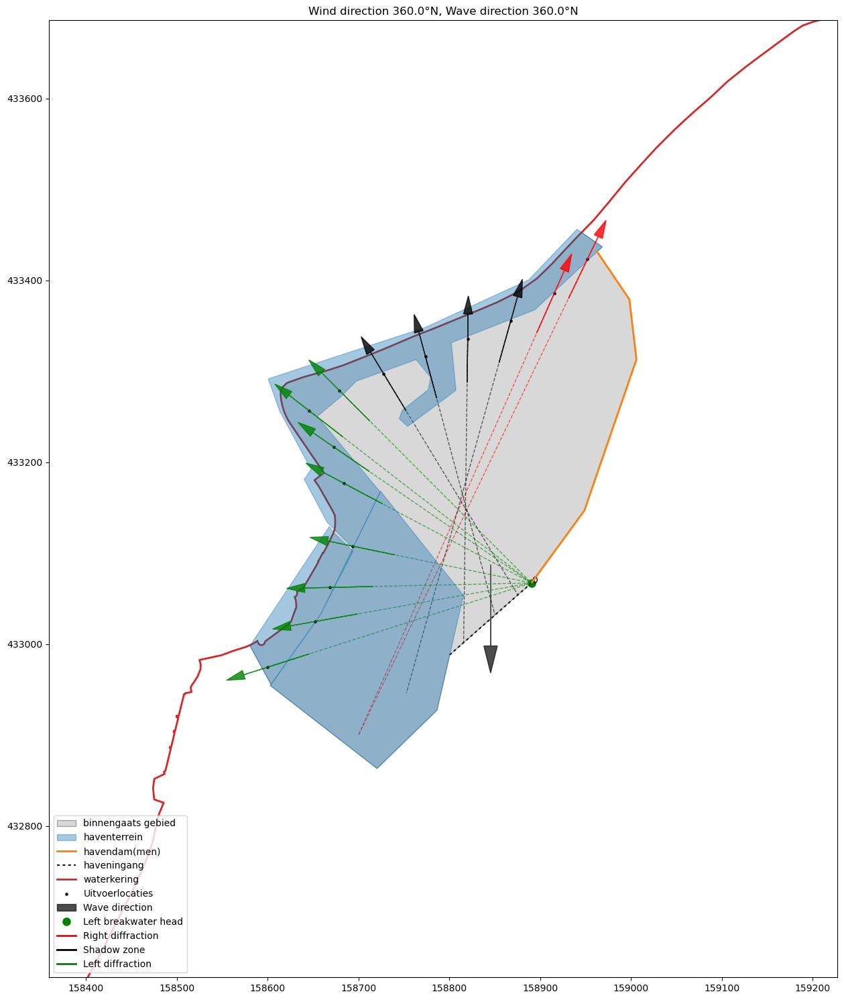

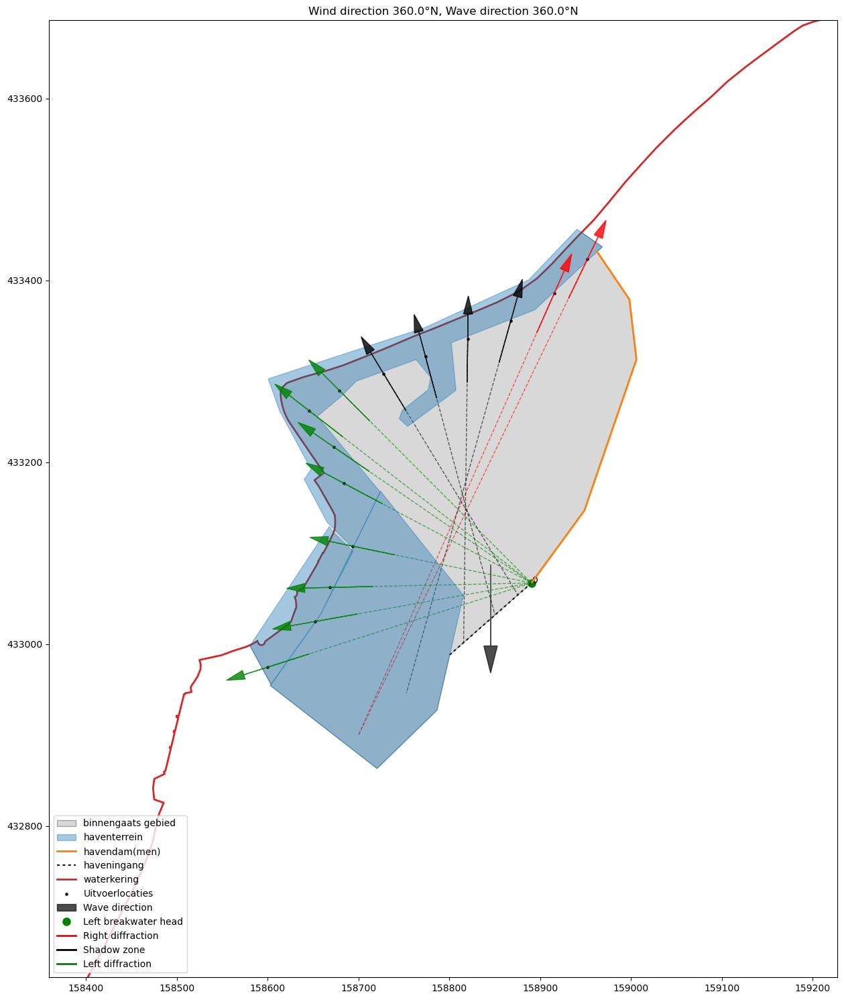

In [ ]:
plot_diffraction_results(model, hlid)